<img src="images/utfsm.png" alt="" width="150px" align="left"/>
<img src="images/utfsm.png" alt="" width="150px" align="right"/>
<br/>
<div align="center">
<h2>IPD-434 Seminario de Soft Computing</h2><br/>
<h1>Certamen - 2026</h1>
<br/><br/>
Dr. Patricio Olivares Roncagliolo<br/><br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María
</div>

- **Alumno**: Francisco Alfaro Medina
- **Rol**: 201110007-7


# Pregunta Lógica Difusa

## Contexto

Usted trabaja para una destacada empresa tecnológica especializada en el desarrollo de sistemas inteligentes para una amplia variedad de electrodomésticos, que incluyen refrigeradores, lavadoras, hornos microondas y aspiradoras, entre otros. Su objetivo es diseñar un sistema de control inteligente que hará uso de la lógica difusa para garantizar un funcionamiento intuitivo y eficiente, considerando las distintas condiciones de uso y las preferencias del usuario.


Para una mejor comprensión del problema, se le presentan tres artículos de divulgación científica que describen sistemas de control inteligente basados en lógica difusa para electrodomésticos. Usted puede basarse en estos artículos para resolver la pregunta o bien utilizarlos como referencia para la búsqueda de un artículo científico que le permita resolver la pregunta.

1. [**Implementation of fuzzy control in a domestic refrigerator considering the influence of the thermal load**](https://doi.org/10.1016/j.ijrefrig.2022.12.018)

2. [**Washing machine using fuzzy logic controller to provide wash quality**](https://doi.org/10.1007/s00500-020-05477-4)

3. [**Rule base reduction for knowledge-based fuzzy controllers with application to a vacuum cleaner**](https://doi.org/10.1016/j.eswa.2004.10.009)

## Objetivo

Su misión consiste en lo siguiente:


### 1. **Especificación del Electrodoméstico y Contexto**

Seleccione el tipo de electrodoméstico en el que se enfocará para la implementación de este sistema de control inteligente. Puede elegir entre refrigeradores, lavadoras, hornos microondas, aspiradoras u otro de su interés. Su elección debe estar respaldada por un trabajo de investigación científica que le servirá de base para responder esta pregunta. Describa el contexto específico en el que operará este electrodoméstico. Por ejemplo, si opta por una lavadora inteligente, podría situarla en un hogar con grandes volúmenes de ropa y diferentes tipos de tejidos.


**Lavadora inteligente** con un controlador de lógica difusa que decide, de forma automática, el programa de lavado (tiempo, temperatura y velocidad de centrifugado) a partir de las características de la carga.

**Contexto de operación**

El sistema operará en un **hogar familiar con grandes volúmenes de ropa y distintos tipos de tejidos** (seda, lana y algodón), donde cada carga varía en peso y en nivel de suciedad. En este escenario el usuario no sabe con precisión cuánto tiempo ni qué temperatura necesita cada carga, y un programa fijo tiende a desperdiciar agua, energía y tiempo en cargas livianas o poco sucias, o a lavar de forma insuficiente las muy sucias. Además, la relación entre cantidad de ropa, suciedad y tiempo de lavado no es una fórmula exacta, por lo que las reglas expresadas en términos lingüísticos ("poca carga", "muy sucia") son una forma natural de modelarla.

**Respaldo científico**
**Artículo base:** Raja, K. y Ramathilagam, S. (2021). *Washing machine using fuzzy logic controller to provide wash quality*. Soft Computing, 25, 9957–9965. https://doi.org/10.1007/s00500-020-05477-4

- Propone un controlador difuso tipo Mamdani con tres entradas (tipo de tela, grado de suciedad y masa de la carga) y salidas como tiempo de lavado, temperatura, RPM y tiempo de secado.
- Define 27 reglas SI-ENTONCES y usa defuzzificación por centroide.
- Su motivación es ahorrar agua, energía y tiempo mediante un lavado ajustado a cada carga.

> **Nota**: Para la implementación en Python con `scikit-fuzzy` se tomaron como referencia técnica algunos repositorios públicos de GitHub. No constituyen respaldo científico; solo sirvieron de guía para la estructura del código.
> - https://github.com/TEL-USM/IPD434/tree/2026-2
> - https://github.com/Sookchand/Fuzzy-Logic-Washing-Machine
> - https://github.com/Guoxuan99/Washing-Machine-Fuzzy-Logic-Controller

### 2. **Diseño e Implementación del Sistema**

Diseñe e implemente un sistema de lógica difusa que contemple al menos dos entradas y al menos dos salidas. Asegúrese de adaptar el sistema para que funcione de manera eficiente, considerando las variables cambiantes del uso o entorno del electrodoméstico, así como las preferencias del usuario.

Se implementa un controlador tipo **Mamdani** con 4 entradas (las 3 del artículo más el modo de lavado elegido por el usuario) y 3 salidas, usando `scikit-fuzzy`, basado en Raja y Ramathilagam (2021).

| Tipo | Variable | Universo | Conjuntos difusos |
|---|---|---|---|
| Entrada | Tipo de tela | 0–10 (delicada → resistente) | seda, lana, algodón |
| Entrada | Nivel de suciedad | 0–100 | no grasosa, media, grasosa |
| Entrada | Carga de ropa | 0–20 kg | baja (<10), media (10–15), alta (>15) |
| Entrada | Modo de lavado (preferencia del usuario) | 0–2 (eco → intensivo) | eco, normal, intensivo |
| Salida | Tiempo de lavado | 0–60 min | muy corto, corto, medio, largo, muy largo |
| Salida | Temperatura | 10–70 °C | fría, tibia, caliente |
| Salida | Velocidad de centrifugado | 400–1400 rpm | baja, media, alta |

El artículo no da los parámetros de las funciones de pertenencia, solo figuras, así que las triangulares/trapezoidales de arriba son definición propia. También tuve que adaptar algunas cosas: el tipo de tela en el paper es categórico y aquí lo pasé a una escala numérica de delicadeza para que siga siendo una variable difusa continua, las etiquetas de RPM (Quick/Intermediate/Long) las dejé como baja/media/alta, y de las 5 salidas que propone el artículo solo implementé 3 (tiempo, temperatura, RPM). La base de reglas sí respeta las 27 reglas originales. La cuarta entrada (`modo`) es una extensión propia para cubrir las preferencias del usuario que pide el enunciado; cómo la integré sin tocar esas 27 reglas se explica más abajo.

El flujo completo del controlador es el siguiente:

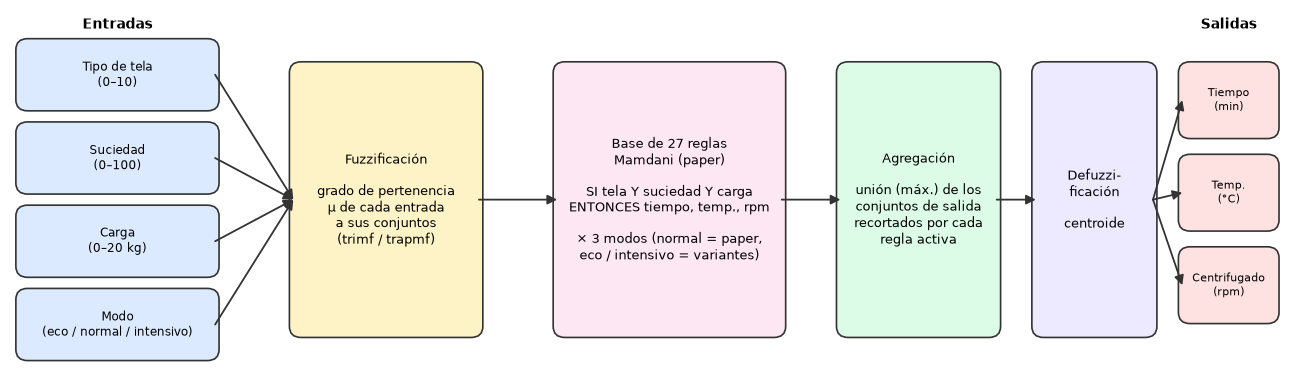

In [1]:
# diagrama de bloques del controlador (graphviz no está instalado, se dibuja con matplotlib)

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13, 4.0))
ax.set_xlim(0, 13); ax.set_ylim(0.6, 4.6); ax.axis('off')

def caja(x, y, w, h, texto, color, fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                fc=color, ec='#333333', lw=1.2))
    ax.text(x + w / 2, y + h / 2, texto, ha='center', va='center', fontsize=fs,
            fontweight='bold' if bold else 'normal')

def flecha(x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>', mutation_scale=14,
                                 lw=1.3, color='#333333', shrinkA=0, shrinkB=0))

# columnas: x inicial y ancho
col = dict(ent=(0.1, 2.0), fuz=(2.9, 1.9), reg=(5.6, 2.3), agr=(8.5, 1.6), dfz=(10.5, 1.2), sal=(12.0, 0.95))

# Entradas
entradas = ['Tipo de tela\n(0–10)', 'Suciedad\n(0–100)', 'Carga\n(0–20 kg)', 'Modo\n(eco / normal / intensivo)']
ys = [3.55, 2.65, 1.75, 0.85]
for t, y in zip(entradas, ys):
    caja(col['ent'][0], y, col['ent'][1], 0.7, t, '#dbeafe', fs=8.5)
ax.text(col['ent'][0] + col['ent'][1] / 2, 4.4, 'Entradas', ha='center', fontweight='bold', fontsize=10)

# Bloques centrales
caja(*(col['fuz'][0], 1.1), col['fuz'][1], 2.9, 'Fuzzificación\n\ngrado de pertenencia\nμ de cada entrada\na sus conjuntos\n(trimf / trapmf)', '#fef3c7', bold=False)
caja(*(col['reg'][0], 1.1), col['reg'][1], 2.9, 'Base de 27 reglas\nMamdani (paper)\n\nSI tela Y suciedad Y carga\nENTONCES tiempo, temp., rpm\n\n× 3 modos (normal = paper,\neco / intensivo = variantes)', '#fce7f3')
caja(*(col['agr'][0], 1.1), col['agr'][1], 2.9, 'Agregación\n\nunión (máx.) de los\nconjuntos de salida\nrecortados por cada\nregla activa', '#dcfce7')
caja(*(col['dfz'][0], 1.1), col['dfz'][1], 2.9, 'Defuzzi-\nficación\n\ncentroide', '#ede9fe')

# Salidas
salidas = ['Tiempo\n(min)', 'Temp.\n(°C)', 'Centrifugado\n(rpm)']
for t, y in zip(salidas, [3.25, 2.25, 1.25]):
    caja(col['sal'][0], y, col['sal'][1], 0.75, t, '#fee2e2', fs=8)
ax.text(col['sal'][0] + col['sal'][1] / 2, 4.4, 'Salidas', ha='center', fontweight='bold', fontsize=10)

# Flechas
for y in ys:
    flecha(col['ent'][0] + col['ent'][1], y + 0.35, col['fuz'][0], 2.55)
for a, b in [('fuz', 'reg'), ('reg', 'agr'), ('agr', 'dfz')]:
    flecha(col[a][0] + col[a][1], 2.55, col[b][0], 2.55)
for y in [3.25, 2.25, 1.25]:
    flecha(col['dfz'][0] + col['dfz'][1], 2.55, col['sal'][0], y + 0.375)

plt.tight_layout(); plt.show()

*Operadores usados (los que trae `scikit-fuzzy` por defecto): AND = mínimo, implicación = recorte del conjunto de salida al grado de activación de la regla, agregación = máximo y defuzzificación por centroide.*

#### Preferencias del usuario: el modo de lavado

El enunciado pide considerar las preferencias del usuario y el paper no las incluye, así que agregué una **cuarta entrada, `modo`** (0 = eco, 1 = normal, 2 = intensivo), con tres conjuntos triangulares que se solapan (eco [0, 0, 1], normal [0, 1, 2], intensivo [1, 2, 2]). La idea es que el usuario elija uno de los tres modos; como los conjuntos se solapan, un valor intermedio (por ejemplo 0.5) mezcla eco y normal, aunque esa interpolación no es el uso previsto (se discute en la sección 3).

Para no romper las 27 reglas del artículo, **no las modifiqué**: pasan a ser el modo `normal` (cada una con el antecedente extra `modo = normal`) y, para `eco` e `intensivo`, generé las mismas 27 reglas con el consecuente desplazado un nivel dentro de su escala (saturando en los extremos, por ejemplo una temperatura "fría" no baja más):

| Modo | Tiempo | Temperatura | Centrifugado |
|---|---|---|---|
| eco | igual | un nivel menos | un nivel menos |
| normal | igual al paper | igual al paper | igual al paper |
| intensivo | un nivel más | un nivel más | igual |

La lógica es que calentar el agua es lo que más energía gasta, así que eco baja la temperatura y centrifuga más suave, pero no acorta el ciclo para no sacrificar la limpieza. Intensivo sube la temperatura y alarga el ciclo para la suciedad difícil, y no sube las RPM porque centrifugar más no limpia más. Los desplazamientos son una decisión de diseño mía (el paper no define modos). En total quedan 3 × 27 = 81 reglas, y con `modo = normal` el sistema da exactamente las mismas salidas que el controlador original de 27 reglas, lo cual verifico en la sección 3 (prueba 7).

In [2]:
!pip3 install scikit-fuzzy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [3]:
# variables y funciones de pertenencia

import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Entradas
tela     = ctrl.Antecedent(np.arange(0, 10.01, 0.1), 'tela')
suciedad = ctrl.Antecedent(np.arange(0, 100.1, 1),   'suciedad')
carga    = ctrl.Antecedent(np.arange(0, 20.01, 0.1), 'carga')
modo     = ctrl.Antecedent(np.arange(0, 2.01, 0.05), 'modo')    # preferencia del usuario: 0 = eco, 1 = normal, 2 = intensivo

# Salidas
tiempo      = ctrl.Consequent(np.arange(0, 60.1, 0.5),     'tiempo')
temperatura = ctrl.Consequent(np.arange(10, 70.1, 0.5),    'temperatura')
rpm         = ctrl.Consequent(np.arange(400, 1400.1, 5),   'rpm')

# Funciones de pertenencia: entradas
tela['seda']    = fuzz.trimf(tela.universe, [0, 0, 5])
tela['lana']    = fuzz.trimf(tela.universe, [0, 5, 10])
tela['algodon'] = fuzz.trimf(tela.universe, [5, 10, 10])

suciedad['no_grasosa'] = fuzz.trimf(suciedad.universe, [0, 0, 50])
suciedad['media']      = fuzz.trimf(suciedad.universe, [0, 50, 100])
suciedad['grasosa']    = fuzz.trimf(suciedad.universe, [50, 100, 100])

carga['baja']  = fuzz.trapmf(carga.universe, [0, 0, 6, 10])
carga['media'] = fuzz.trimf(carga.universe,  [7, 12.5, 18])
carga['alta']  = fuzz.trapmf(carga.universe, [14, 17, 20, 20])

modo['eco']       = fuzz.trimf(modo.universe, [0, 0, 1])
modo['normal']    = fuzz.trimf(modo.universe, [0, 1, 2])
modo['intensivo'] = fuzz.trimf(modo.universe, [1, 2, 2])

# Funciones de pertenencia: salidas
tiempo['muy_corto'] = fuzz.trimf(tiempo.universe, [0, 0, 15])
tiempo['corto']     = fuzz.trimf(tiempo.universe, [0, 15, 30])
tiempo['medio']     = fuzz.trimf(tiempo.universe, [15, 30, 45])
tiempo['largo']     = fuzz.trimf(tiempo.universe, [30, 45, 60])
tiempo['muy_largo'] = fuzz.trimf(tiempo.universe, [45, 60, 60])

temperatura['fria']     = fuzz.trimf(temperatura.universe, [10, 10, 40])
temperatura['tibia']    = fuzz.trimf(temperatura.universe, [10, 40, 70])
temperatura['caliente'] = fuzz.trimf(temperatura.universe, [40, 70, 70])

rpm['baja']  = fuzz.trimf(rpm.universe, [400, 400, 900])
rpm['media'] = fuzz.trimf(rpm.universe, [400, 900, 1400])
rpm['alta']  = fuzz.trimf(rpm.universe, [900, 1400, 1400])

/Users/franciscoalfaro/Documents/00_fralfaro/IPD434/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


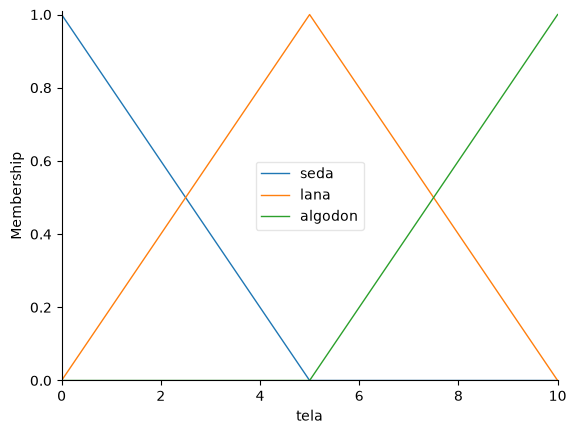

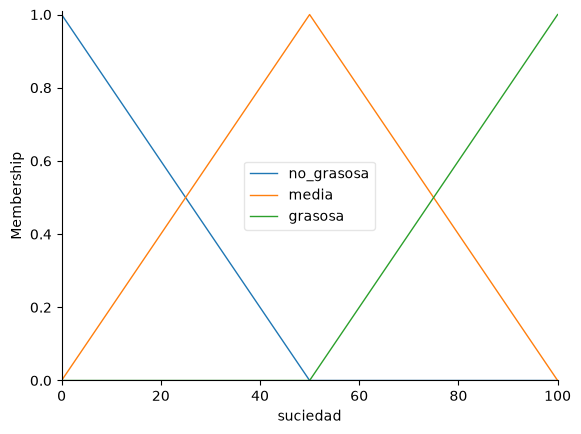

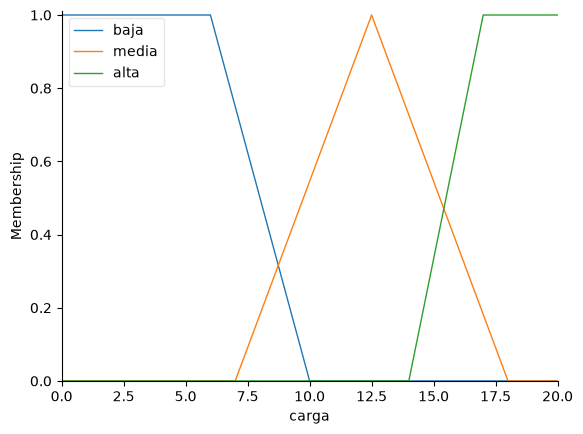

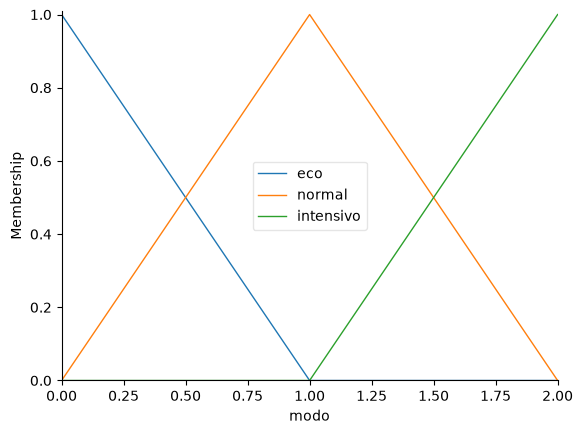

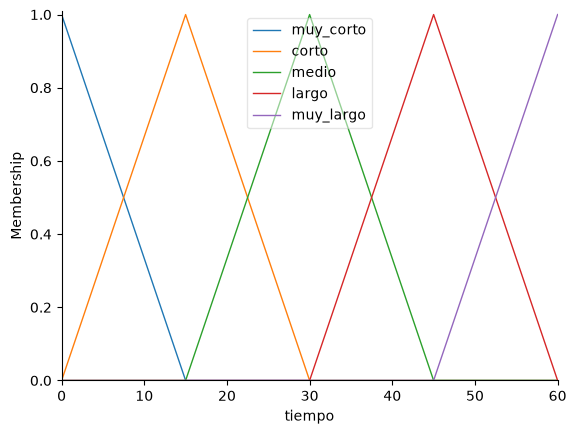

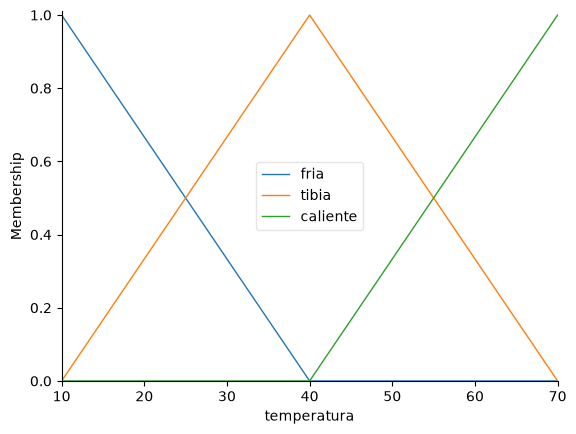

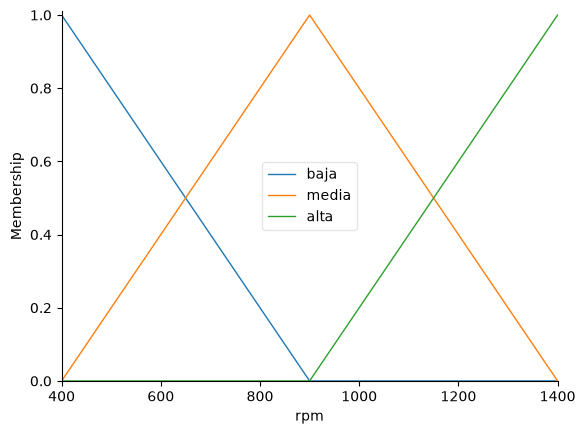

In [4]:
# gráficos de las funciones de pertenencia

for var in [tela, suciedad, carga, modo, tiempo, temperatura, rpm]:
    var.view()

In [5]:
# tabla de reglas (Tabla de reglas del artículo, 27 filas)

reglas_df = pd.DataFrame([
 # tela,     suciedad,     carga,   tiempo,      temperatura, rpm
 ('seda',    'no_grasosa', 'baja',  'muy_corto', 'fria',     'baja'),
 ('seda',    'no_grasosa', 'media', 'corto',     'fria',     'media'),
 ('seda',    'no_grasosa', 'alta',  'medio',     'tibia',    'media'),
 ('seda',    'media',      'baja',  'medio',     'fria',     'baja'),
 ('seda',    'media',      'media', 'largo',     'fria',     'alta'),
 ('seda',    'media',      'alta',  'largo',     'tibia',    'media'),
 ('seda',    'grasosa',    'baja',  'medio',     'fria',     'alta'),
 ('seda',    'grasosa',    'media', 'largo',     'tibia',    'alta'),
 ('seda',    'grasosa',    'alta',  'muy_largo', 'tibia',    'alta'),
 ('lana',    'no_grasosa', 'baja',  'corto',     'tibia',    'baja'),
 ('lana',    'no_grasosa', 'media', 'medio',     'tibia',    'media'),
 ('lana',    'no_grasosa', 'alta',  'largo',     'tibia',    'alta'),
 ('lana',    'media',      'baja',  'medio',     'tibia',    'media'),
 ('lana',    'media',      'media', 'medio',     'tibia',    'media'),
 ('lana',    'media',      'alta',  'largo',     'tibia',    'alta'),
 ('lana',    'grasosa',    'baja',  'largo',     'caliente', 'alta'),
 ('lana',    'grasosa',    'media', 'largo',     'caliente', 'alta'),
 ('lana',    'grasosa',    'alta',  'muy_largo', 'caliente', 'alta'),
 ('algodon', 'no_grasosa', 'baja',  'corto',     'tibia',    'baja'),
 ('algodon', 'no_grasosa', 'media', 'medio',     'tibia',    'media'),
 ('algodon', 'no_grasosa', 'alta',  'largo',     'tibia',    'alta'),
 ('algodon', 'media',      'baja',  'medio',     'tibia',    'media'),
 ('algodon', 'media',      'media', 'largo',     'tibia',    'alta'),
 ('algodon', 'media',      'alta',  'muy_largo', 'tibia',    'alta'),
 ('algodon', 'grasosa',    'baja',  'largo',     'caliente', 'alta'),
 ('algodon', 'grasosa',    'media', 'largo',     'caliente', 'alta'),
 ('algodon', 'grasosa',    'alta',  'muy_largo', 'caliente', 'alta'),
], columns=['tela', 'suciedad', 'carga', 'tiempo', 'temperatura', 'rpm'])

reglas_df

,tela,suciedad,carga,tiempo,temperatura,rpm
0,seda,no_grasosa,baja,muy_corto,fria,baja
1,seda,no_grasosa,media,corto,fria,media
2,seda,no_grasosa,alta,medio,tibia,media
3,seda,media,baja,medio,fria,baja
4,seda,media,media,largo,fria,alta
5,seda,media,alta,largo,tibia,media
6,seda,grasosa,baja,medio,fria,alta
7,seda,grasosa,media,largo,tibia,alta
8,seda,grasosa,alta,muy_largo,tibia,alta
9,lana,no_grasosa,baja,corto,tibia,baja


In [6]:
# generación de reglas y sistema de control

# 1) Sistema base: las 27 reglas del artículo tal cual (3 entradas). Se conserva solo como referencia
#    para comprobar más adelante que el modo "normal" reproduce exactamente el paper.
reglas_base = []
for _, r in reglas_df.iterrows():
    antecedente = tela[r.tela] & suciedad[r.suciedad] & carga[r.carga]
    reglas_base.append(ctrl.Rule(antecedente, tiempo[r.tiempo]))
    reglas_base.append(ctrl.Rule(antecedente, temperatura[r.temperatura]))
    reglas_base.append(ctrl.Rule(antecedente, rpm[r.rpm]))
sistema_base = ctrl.ControlSystem(reglas_base)
sim_base = ctrl.ControlSystemSimulation(sistema_base)

# 2) Sistema con modo: mismas 27 reglas x 3 modos. El modo desplaza el consecuente un nivel
#    dentro de su escala ordenada (saturando en los extremos).
NIVELES = {'tiempo':      ['muy_corto', 'corto', 'medio', 'largo', 'muy_largo'],
           'temperatura': ['fria', 'tibia', 'caliente'],
           'rpm':         ['baja', 'media', 'alta']}
DESPLAZ = {'eco':       {'tiempo': 0,  'temperatura': -1, 'rpm': -1},
           'normal':    {'tiempo': 0,  'temperatura': 0,  'rpm': 0},
           'intensivo': {'tiempo': +1, 'temperatura': +1, 'rpm': 0}}

def desplazar(etiqueta, variable, m):
    niv = NIVELES[variable]
    return niv[min(max(niv.index(etiqueta) + DESPLAZ[m][variable], 0), len(niv) - 1)]

filas = []
for m in ['eco', 'normal', 'intensivo']:
    for _, r in reglas_df.iterrows():
        filas.append(dict(modo=m, tela=r.tela, suciedad=r.suciedad, carga=r.carga,
                          tiempo=desplazar(r.tiempo, 'tiempo', m),
                          temperatura=desplazar(r.temperatura, 'temperatura', m),
                          rpm=desplazar(r.rpm, 'rpm', m)))
reglas_modo_df = pd.DataFrame(filas)

# las 27 reglas del paper quedan intactas como modo "normal"
assert (reglas_modo_df[reglas_modo_df.modo == 'normal'].drop(columns='modo')
        .reset_index(drop=True).equals(reglas_df))

reglas = []
for _, r in reglas_modo_df.iterrows():
    antecedente = tela[r.tela] & suciedad[r.suciedad] & carga[r.carga] & modo[r.modo]
    # una sola regla con las tres salidas (equivale a tres reglas simples, pero evalúa el antecedente una vez)
    reglas.append(ctrl.Rule(antecedente, [tiempo[r.tiempo], temperatura[r.temperatura], rpm[r.rpm]]))

sistema = ctrl.ControlSystem(reglas)
simulacion = ctrl.ControlSystemSimulation(sistema)
print(f"{len(reglas_df)} reglas del paper (sistema base, {len(reglas_base)} reglas simples)")
print(f"{len(reglas)} reglas con modo = 27 x 3 modos (cada una con las 3 salidas)")

27 reglas del paper (sistema base, 81 reglas simples)
81 reglas con modo = 27 x 3 modos (cada una con las 3 salidas)


In [7]:
# prueba rápida

MODOS = {'eco': 0, 'normal': 1, 'intensivo': 2}

def lavar(t, s, c, m='normal'):
    """m: 'eco' | 'normal' | 'intensivo', o un número en [0, 2] (perilla continua)."""
    simulacion.inputs({'tela': t, 'suciedad': s, 'carga': c, 'modo': MODOS.get(m, m)})
    simulacion.compute()
    o = simulacion.output
    return (round(float(o['tiempo']), 1), round(float(o['temperatura']), 1), round(float(o['rpm']), 1))

def lavar_base(t, s, c):
    """Controlador original del paper (27 reglas, sin modo)."""
    sim_base.inputs({'tela': t, 'suciedad': s, 'carga': c})
    sim_base.compute()
    o = sim_base.output
    return (round(float(o['tiempo']), 1), round(float(o['temperatura']), 1), round(float(o['rpm']), 1))

print(lavar(0, 0, 5))     # seda, limpia, poca carga
print(lavar(10, 100, 18)) # algodón, muy sucio, carga alta
print("Lana, suciedad 50, 12 kg  ->  eco:", lavar(5, 50, 12, 'eco'),
      "| normal:", lavar(5, 50, 12, 'normal'), "| intensivo:", lavar(5, 50, 12, 'intensivo'))

(5.0, 20.0, 566.7)
(55.0, 60.0, 1233.3)
Lana, suciedad 50, 12 kg  ->  eco: (30.0, 20.1, 567.9) | normal: (30.0, 40.0, 900.0) | intensivo: (45.0, 59.9, 900.0)


#### Inferencia paso a paso de un caso

Para ver cómo se llega a un resultado tomo un caso concreto: una tela entre lana y algodón (7), suciedad entre media y grasosa (65), carga media-baja (11 kg) y modo normal. Se muestran los cuatro pasos de Mamdani: (1) fuzzificación de las entradas, (2) reglas que se activan y con qué fuerza, (3) agregación de los consecuentes recortados y (4) defuzzificación por centroide. Los gráficos de `.view(sim=...)` marcan con una línea negra el valor de entrada sobre sus conjuntos (con el grado de activación sombreado) y, en las salidas, el área agregada y su centroide (línea negra).

Paso 1 - fuzzificación
  tela = 7  ->  lana: 0.60, algodon: 0.40
  suciedad = 65  ->  media: 0.70, grasosa: 0.30
  carga = 11  ->  media: 0.73
  modo = 1  ->  normal: 1.00

Paso 2 - 4 reglas activas


,modo,tela,suciedad,carga,tiempo,temperatura,rpm,fuerza
40,normal,lana,media,media,medio,tibia,media,0.6
49,normal,algodon,media,media,largo,tibia,alta,0.4
43,normal,lana,grasosa,media,largo,caliente,alta,0.3
52,normal,algodon,grasosa,media,largo,caliente,alta,0.3


Pasos 3 y 4 - salidas (centroide): {'tiempo': 36.3, 'temperatura': 41.4, 'rpm': 937.7}


/Users/franciscoalfaro/Documents/00_fralfaro/IPD434/.venv/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


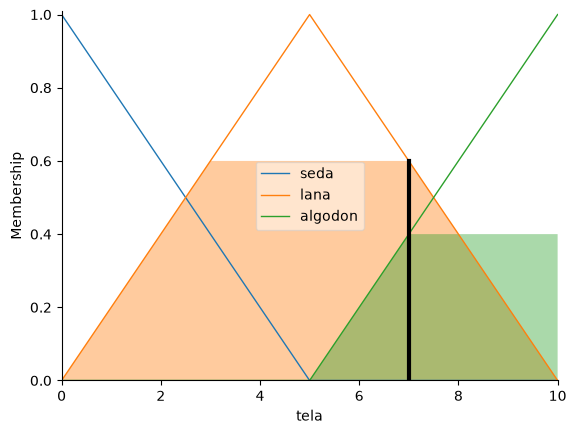

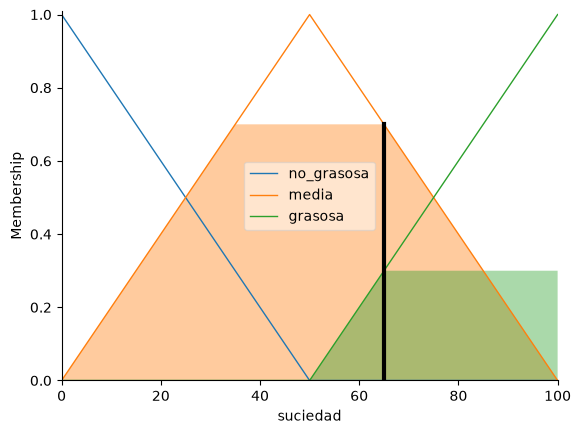

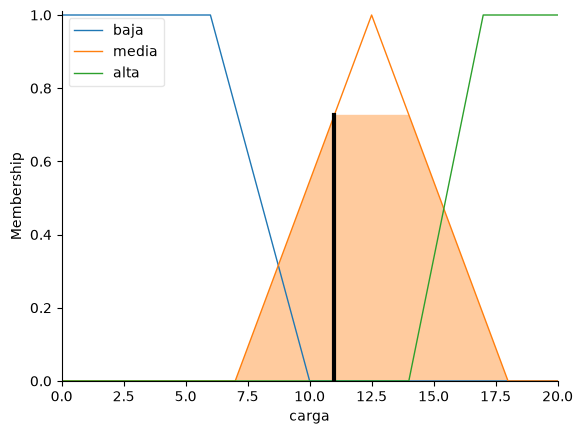

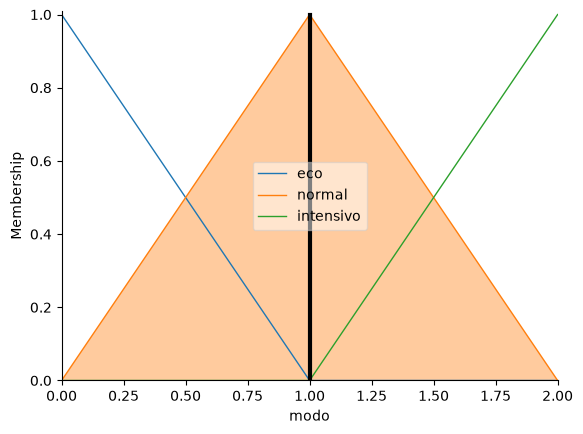

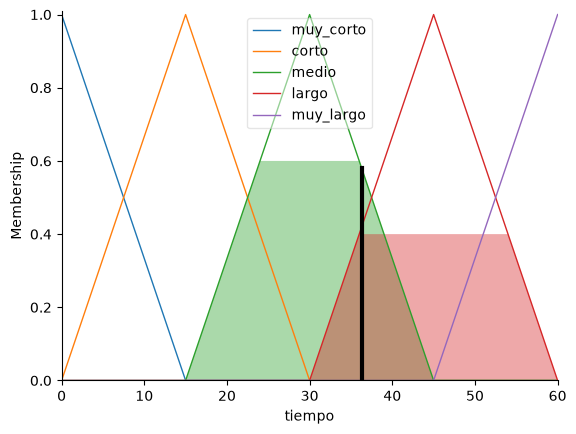

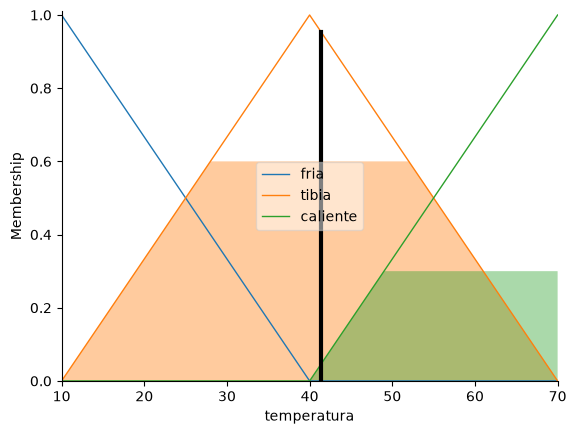

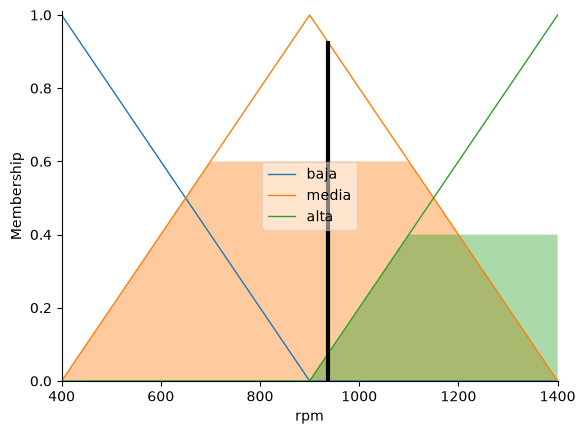

In [8]:
# inferencia paso a paso de un caso (usa .view() de scikit-fuzzy)

caso = dict(tela=7, suciedad=65, carga=11, modo=1)
simulacion.inputs(caso)
simulacion.compute()

# Paso 1: fuzzificación (grado de pertenencia de cada entrada a sus conjuntos)
vars_in = {'tela': tela, 'suciedad': suciedad, 'carga': carga, 'modo': modo}
mu = {nombre: {t: float(fuzz.interp_membership(v.universe, v[t].mf, caso[nombre])) for t in v.terms}
      for nombre, v in vars_in.items()}
print("Paso 1 - fuzzificación")
for nombre, g in mu.items():
    print(f"  {nombre} = {caso[nombre]}  ->  " + ", ".join(f"{t}: {x:.2f}" for t, x in g.items() if x > 0))

# Paso 2: reglas activas (fuerza = mínimo de los grados de los antecedentes)
act = reglas_modo_df.copy()
act['fuerza'] = [min(mu['tela'][r.tela], mu['suciedad'][r.suciedad], mu['carga'][r.carga], mu['modo'][r.modo])
                 for r in act.itertuples()]
act = act[act.fuerza > 1e-9].sort_values('fuerza', ascending=False).round(2)
print(f"\nPaso 2 - {len(act)} reglas activas")
display(act)

# Paso 3 y 4: agregación y defuzzificación (centroide), con los gráficos de scikit-fuzzy
res = {k: round(float(v), 1) for k, v in simulacion.output.items()}
print("Pasos 3 y 4 - salidas (centroide):", res)
for v in (tela, suciedad, carga, modo, tiempo, temperatura, rpm):
    v.view(sim=simulacion)

### 3. **Pruebas y Validación**

Implemente su sistema de lógica difusa utilizando la biblioteca scikit-fuzzy. Luego, realice pruebas exhaustivas para demostrar su eficacia en diversas condiciones de operación.

El controlador se implementó con `scikit-fuzzy` (Mamdani, centroide). Para evaluarlo se aplicaron siete pruebas:

1. **Casos representativos:** escenarios realistas de uso doméstico, en modo normal y comparados en los tres modos.
2. **Consistencia con la base de reglas:** al evaluar el centro de cada una de las 81 reglas (27 del paper × 3 modos), la salida debe coincidir con la etiqueta que la regla indica. Se acompaña de un mapa de calor de la base de reglas.
3. **Barridos de sensibilidad:** al variar una entrada y fijar las demás, las salidas deben variar de forma coherente (monotonía). Incluye un barrido del modo para ver qué pasa entre eco, normal e intensivo.
4. **Superficies de control:** relación entrada-salida en todo el dominio.
5. **Cobertura y robustez:** entradas aleatorias en todo el dominio, y ruido de ±5 % en los sensores.
6. **Comparación con un programa fijo:** referencia hipotética de 45 min y 60 °C.
7. **Modo de lavado:** con `modo = normal` el controlador debe reproducir exactamente el del paper, y entre modos las salidas deben mantener el orden esperado (eco ≤ normal ≤ intensivo).

In [9]:
# casos representativos*

casos = pd.DataFrame([
 ('Camisa de seda, casi limpia, poca carga',            0,   5,  4),
 ('Seda manchada con grasa, carga media',               0,  90, 12),
 ('Lana de uso diario, carga media',                    5,  50, 12),
 ('Lana muy sucia, carga baja',                         5,  95,  5),
 ('Algodón poco sucio, carga baja',                    10,  10,  6),
 ('Algodón de uso normal, carga media',                10,  50, 12),
 ('Ropa de trabajo (algodón grasoso), carga alta',     10,  95, 18),
 ('Carga máxima, tela intermedia, suciedad media',      5,  50, 20),
], columns=['Escenario', 'tela', 'suciedad', 'carga'])

res = casos.apply(lambda r: lavar(r.tela, r.suciedad, r.carga), axis=1, result_type='expand')
casos[['Tiempo (min)', 'Temp (°C)', 'RPM']] = res.round(1)
casos

,Escenario,tela,suciedad,carga,Tiempo (min),Temp (°C),RPM
0,"Camisa de seda, casi limpia, poca carga",0,5,4,12.0,20.1,568.2
1,"Seda manchada con grasa, carga media",0,90,12,45.0,39.4,1227.8
2,"Lana de uso diario, carga media",5,50,12,30.0,40.0,900.0
3,"Lana muy sucia, carga baja",5,95,5,43.0,54.3,1138.2
4,"Algodón poco sucio, carga baja",10,10,6,18.6,40.0,727.5
5,"Algodón de uso normal, carga media",10,50,12,45.0,40.0,1232.1
6,"Ropa de trabajo (algodón grasoso), carga alta",10,95,18,55.0,54.3,1231.8
7,"Carga máxima, tela intermedia, suciedad media",5,50,20,45.0,40.0,1233.3


In [10]:
# los mismos casos en los tres modos

tabla_modos = pd.concat(
    {m: pd.DataFrame([lavar(r.tela, r.suciedad, r.carga, m) for r in casos.itertuples()],
                     columns=['Tiempo (min)', 'Temp (°C)', 'RPM'])
     for m in MODOS}, axis=1)
tabla_modos.index = casos['Escenario']
tabla_modos

eco                   \
                                              Tiempo (min) Temp (°C)    RPM   
Escenario                                                                     
Camisa de seda, casi limpia, poca carga               12.0      20.1  568.2   
Seda manchada con grasa, carga media                  45.0      20.3  900.0   
Lana de uso diario, carga media                       30.0      20.1  567.9   
Lana muy sucia, carga baja                            43.0      39.9  897.6   
Algodón poco sucio, carga baja                        18.6      20.3  572.2   
Algodón de uso normal, carga media                    45.0      20.1  900.0   
Ropa de trabajo (algodón grasoso), carga alta         55.0      39.9  900.0   
Carga máxima, tela intermedia, suciedad media         45.0      20.0  900.0   

                                                    normal                    \
                                              Tiempo (min) Temp (°C)     RPM   
Escenario                                                                      
Camisa de seda, casi limpia, poca carga               12.0      20.1   568.2   
Seda manchada con grasa, carga media                  45.0      39.4  1227.8   
Lana de uso diario, carga media                       30.0      40.0   900.0   
Lana muy sucia, carga baja                            43.0      54.3  1138.2   
Algodón poco sucio, carga baja                        18.6      40.0   727.5   
Algodón de uso normal, carga media                    45.0      40.0  1232.1   
Ropa de trabajo (algodón grasoso), carga alta         55.0      54.3  1231.8   
Carga máxima, tela intermedia, suciedad media         45.0      40.0  1233.3   

                                                 intensivo                    
                                              Tiempo (min) Temp (°C)     RPM  
Escenario                                                                     
Camisa de seda, casi limpia, poca carga               19.8      40.0   568.2  
Seda manchada con grasa, carga media                  54.8      50.4  1227.8  
Lana de uso diario, carga media                       45.0      59.9   900.0  
Lana muy sucia, carga baja                            52.1      59.9  1138.2  
Algodón poco sucio, carga baja                        33.6      59.7   727.5  
Algodón de uso normal, carga media                    55.0      59.9  1232.1  
Ropa de trabajo (algodón grasoso), carga alta         55.0      59.9  1231.8  
Carga máxima, tela intermedia, suciedad media         55.0      60.0  1233.3

El modo mueve las salidas en el sentido diseñado. Por ejemplo, la lana de uso diario (caso 2) pasa de 40 °C y 900 rpm en normal a 20 °C y 568 rpm en eco, y a 59.9 °C y 45 min (desde 30) en intensivo. En eco el tiempo no cambia (así se definió), y en los casos que ya estaban en el extremo de una escala el modo no puede empujar más, porque el desplazamiento satura.

In [11]:
# consistencia con las reglas (evaluación en el centro de cada regla), en los tres modos

centros = {'tela': {'seda': 0, 'lana': 5, 'algodon': 10},
           'suciedad': {'no_grasosa': 0, 'media': 50, 'grasosa': 100},
           'carga': {'baja': 3, 'media': 12.5, 'alta': 18.5}}
pico_t  = {'muy_corto': 0, 'corto': 15, 'medio': 30, 'largo': 45, 'muy_largo': 60}
pico_te = {'fria': 10, 'tibia': 40, 'caliente': 70}
pico_r  = {'baja': 400, 'media': 900, 'alta': 1400}
cercano = lambda v, d: min(d, key=lambda k: abs(d[k] - v))

total_ok = 0
for m in MODOS:
    aciertos = 0
    sub = reglas_modo_df[reglas_modo_df.modo == m]
    for _, r in sub.iterrows():
        t, te, rp = lavar(centros['tela'][r.tela], centros['suciedad'][r.suciedad], centros['carga'][r.carga], m)
        aciertos += (cercano(t, pico_t) == r.tiempo) + (cercano(te, pico_te) == r.temperatura) + (cercano(rp, pico_r) == r.rpm)
    total_ok += aciertos
    print(f"Modo {m:9s}: salidas consistentes con su regla: {aciertos} de {len(sub)*3}")
print(f"Total: {total_ok} de {len(reglas_modo_df)*3}")

Modo eco      : salidas consistentes con su regla: 81 de 81


Modo normal   : salidas consistentes con su regla: 81 de 81


Modo intensivo: salidas consistentes con su regla: 81 de 81
Total: 243 de 243


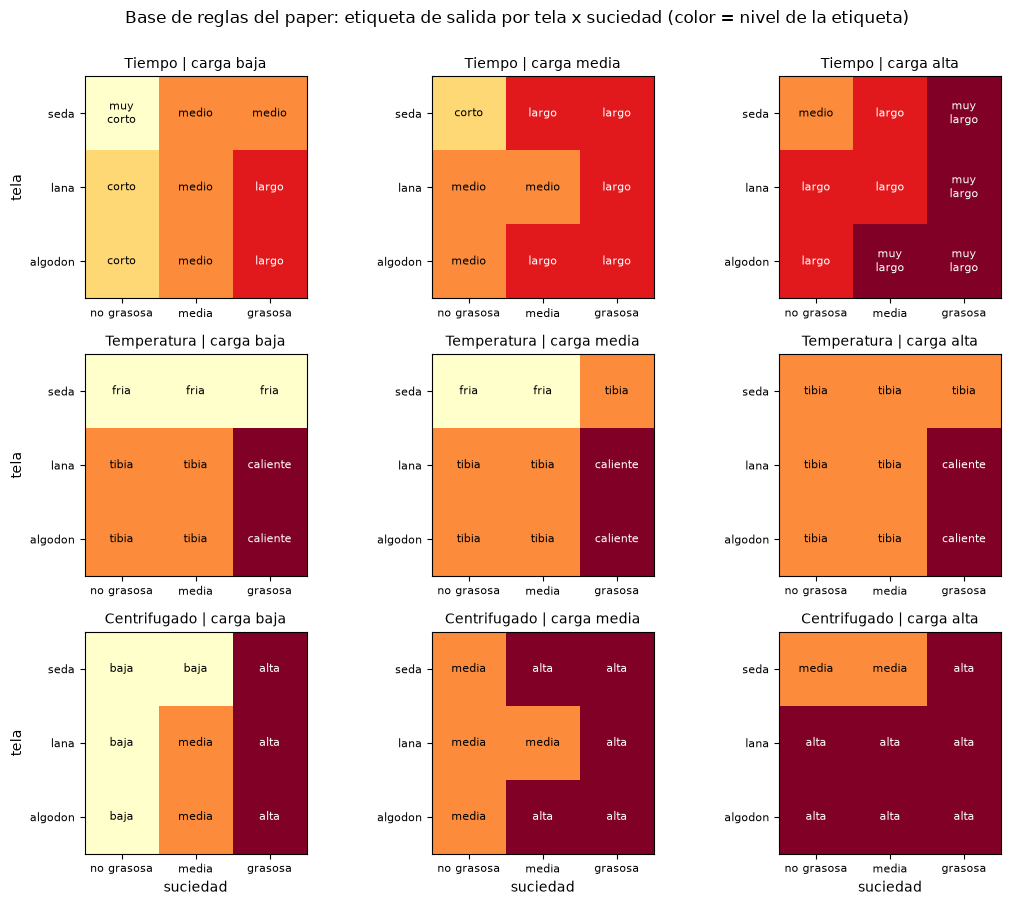

In [12]:
# mapa de calor de la base de reglas (las 27 reglas del paper = modo normal): tela x suciedad, una figura por salida y carga

telas, sucs, cargas = ['seda', 'lana', 'algodon'], ['no_grasosa', 'media', 'grasosa'], ['baja', 'media', 'alta']
lut = {(r.tela, r.suciedad, r.carga): r for r in reglas_df.itertuples()}
nombres_sal = {'tiempo': 'Tiempo', 'temperatura': 'Temperatura', 'rpm': 'Centrifugado'}

fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for i, sal in enumerate(NIVELES):
    niv = NIVELES[sal]
    for j, c in enumerate(cargas):
        M = np.array([[niv.index(getattr(lut[(t, s, c)], sal)) for s in sucs] for t in telas])
        ax = axes[i, j]
        ax.imshow(M, cmap='YlOrRd', vmin=0, vmax=len(niv) - 1)
        for a in range(3):
            for b in range(3):
                ax.text(b, a, niv[M[a, b]].replace('_', '\n'), ha='center', va='center', fontsize=8,
                        color='white' if M[a, b] >= 0.75 * (len(niv) - 1) else 'black')
        ax.set_xticks(range(3)); ax.set_xticklabels([s.replace('_', ' ') for s in sucs], fontsize=8)
        ax.set_yticks(range(3)); ax.set_yticklabels(telas, fontsize=8)
        ax.set_title(f"{nombres_sal[sal]} | carga {c}", fontsize=10)
        if i == 2: ax.set_xlabel('suciedad')
        if j == 0: ax.set_ylabel('tela')
plt.suptitle('Base de reglas del paper: etiqueta de salida por tela x suciedad (color = nivel de la etiqueta)', y=1.0)
plt.tight_layout(); plt.show()

El mapa de calor deja ver la estructura de la base de reglas del paper: el tiempo y el centrifugado crecen hacia la esquina de más suciedad y más carga, y la temperatura solo llega a "caliente" con suciedad grasosa en lana y algodón (la seda nunca pasa de "tibia"). También se ven rarezas heredadas del paper, por ejemplo con carga media y suciedad media la seda tiene tiempo "largo" y la lana "medio", aunque la seda es más delicada. Como esas 27 reglas no se podían modificar, las dejé tal cual.

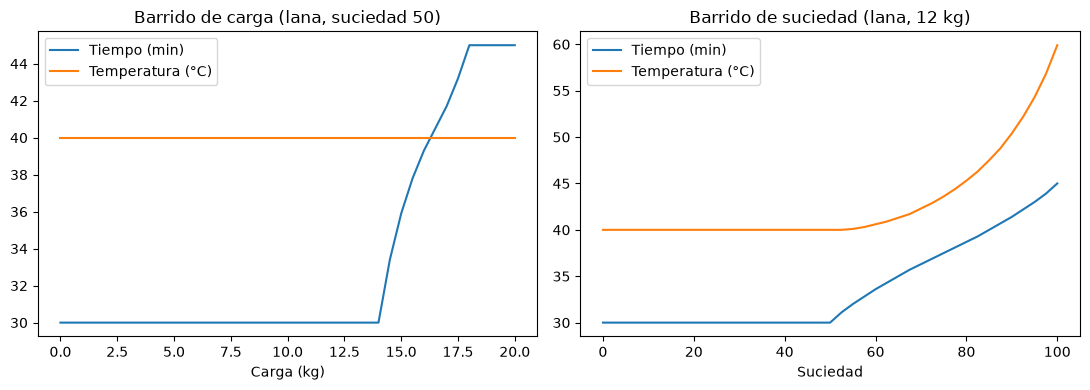

Tiempo no decrece con la carga:      True
Tiempo no decrece con la suciedad:   True
Temp. no decrece con la suciedad:    True


In [13]:
# barridos de sensibilidad

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

cs = np.linspace(0, 20, 41)
b = np.array([lavar(5, 50, c) for c in cs])
ax[0].plot(cs, b[:, 0], label='Tiempo (min)'); ax[0].plot(cs, b[:, 1], label='Temperatura (°C)')
ax[0].set_xlabel('Carga (kg)'); ax[0].set_title('Barrido de carga (lana, suciedad 50)'); ax[0].legend()

ss = np.linspace(0, 100, 41)
b2 = np.array([lavar(5, s, 12) for s in ss])
ax[1].plot(ss, b2[:, 0], label='Tiempo (min)'); ax[1].plot(ss, b2[:, 1], label='Temperatura (°C)')
ax[1].set_xlabel('Suciedad'); ax[1].set_title('Barrido de suciedad (lana, 12 kg)'); ax[1].legend()
plt.tight_layout(); plt.show()

print("Tiempo no decrece con la carga:     ", np.all(np.diff(b[:, 0])  >= -1e-6))
print("Tiempo no decrece con la suciedad:  ", np.all(np.diff(b2[:, 0]) >= -1e-6))
print("Temp. no decrece con la suciedad:   ", np.all(np.diff(b2[:, 1]) >= -1e-6))



Seda limpia, 5 kg          mayor caída al subir el modo (tiempo, temp., rpm): [0.5 0.3 4.5]


Lana, suciedad 50, 12 kg   mayor caída al subir el modo (tiempo, temp., rpm): [0. 0. 0.]


Algodón muy sucio, 18 kg   mayor caída al subir el modo (tiempo, temp., rpm): [0.2 0.6 4.5]


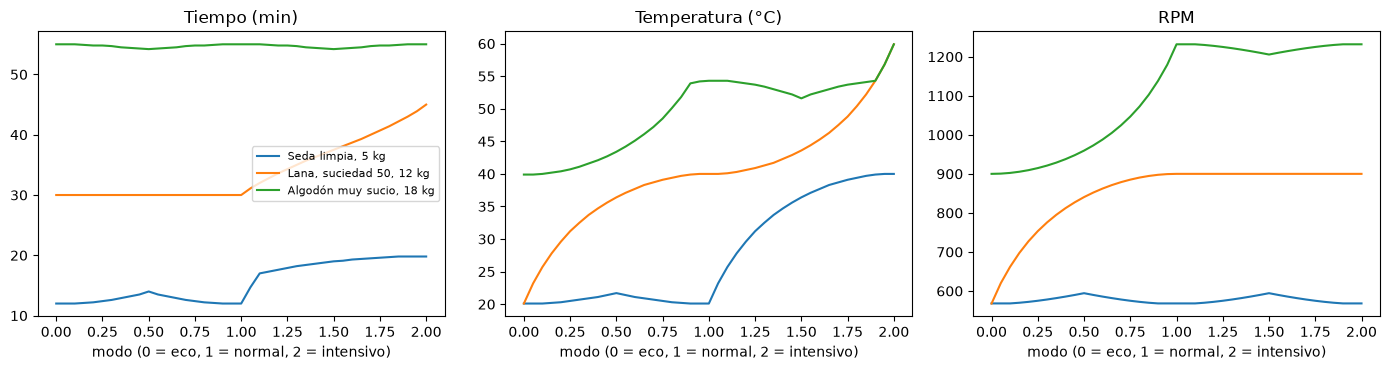

In [14]:
# barrido del modo: valores intermedios entre eco (0), normal (1) e intensivo (2)

ms = np.linspace(0, 2, 41)
perilla = {'Seda limpia, 5 kg': (0, 5, 5), 'Lana, suciedad 50, 12 kg': (5, 50, 12), 'Algodón muy sucio, 18 kg': (10, 95, 18)}
etiquetas = ['Tiempo (min)', 'Temperatura (°C)', 'RPM']

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for nombre, x in perilla.items():
    b = np.array([lavar(*x, m) for m in ms])
    for k in range(3):
        ax[k].plot(ms, b[:, k], label=nombre)
    caida = [float(max(0, -np.diff(b[:, k]).min())) for k in range(3)]     # mayor caída entre dos pasos consecutivos
    print(f"{nombre:26s} mayor caída al subir el modo (tiempo, temp., rpm): {np.round(caida, 1)}")
for k in range(3):
    ax[k].set_xlabel('modo (0 = eco, 1 = normal, 2 = intensivo)'); ax[k].set_title(etiquetas[k])
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

En los tres modos discretos (0, 1 y 2) las salidas siguen el orden esperado, pero entre ellos el barrido muestra que la interpolación no es estrictamente monótona: en dos de los tres casos hay pequeñas caídas al subir el modo (hasta 0.6 °C en temperatura, 0.5 min en tiempo y 4.5 rpm), y en la lana sí es monótono. Se debe a que con valores intermedios se activan a la vez dos conjuntos de reglas con fuerza parcial y el centroide de un conjunto recortado se desplaza. Son diferencias chicas, pero por eso presento el modo como un selector de tres posiciones y no como una perilla continua.

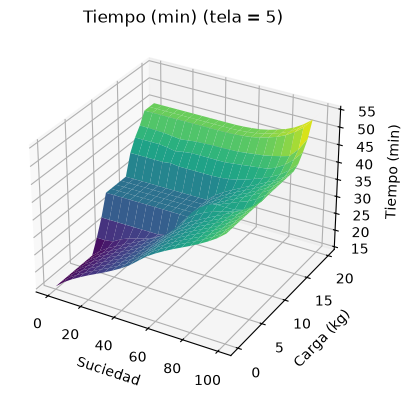

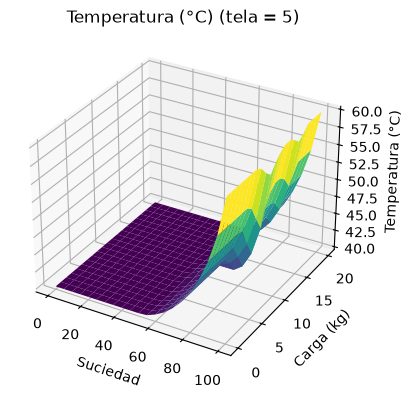

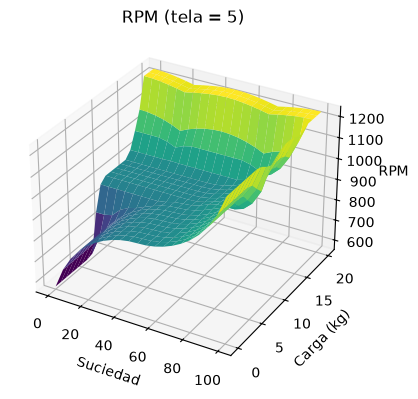

In [15]:
# superficies de control

def superficie(idx, nombre, tela_fija):
    xs, ys = np.linspace(0, 100, 21), np.linspace(0, 20, 21)
    Z = np.array([[lavar(tela_fija, x, y)[idx] for x in xs] for y in ys])
    X, Y = np.meshgrid(xs, ys)
    fig = plt.figure(figsize=(6, 4.5)); ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='viridis')
    ax.set_xlabel('Suciedad'); ax.set_ylabel('Carga (kg)'); ax.set_zlabel(nombre)
    ax.set_title(f'{nombre} (tela = {tela_fija})'); plt.show()

for idx, nombre in enumerate(['Tiempo (min)', 'Temperatura (°C)', 'RPM']):
    superficie(idx, nombre, tela_fija=5)



In [16]:
# cobertura y robustez

rng = np.random.default_rng(42)

# Cobertura: 500 entradas aleatorias en todo el dominio
X = np.c_[rng.uniform(0, 10, 500), rng.uniform(0, 100, 500), rng.uniform(0, 20, 500)]
Y = np.array([lavar(*x) for x in X])
print("Todas las salidas son finitas:", np.isfinite(Y).all())
print("Rango de salidas  min:", Y.min(0).round(1), " max:", Y.max(0).round(1))

# Robustez: ruido gaussiano de 5 % en los sensores, sobre un caso base
base = np.array([5, 60, 12])
ruido = np.array([lavar(*np.clip(base * (1 + rng.normal(0, 0.05, 3)), [0, 0, 0], [10, 100, 20]))
                  for _ in range(200)])
print("Caso base:", np.round(lavar(*base), 1))
print("Coef. de variación (%):", (100 * ruido.std(0) / ruido.mean(0)).round(2))



Todas las salidas son finitas: True
Rango de salidas  min: [ 11.8  21.8 570.1]  max: [  54.1   58.7 1230.4]


Caso base: [ 33.6  40.6 909.5]
Coef. de variación (%): [2.64 0.75 0.55]


In [17]:
# comparación con un programa fijo


# Programa fijo hipotético: 45 min, 60 °C (supuesto de referencia, no medido)
ahorro_t  = 100 * (1 - Y[:, 0] / 45).mean()
ahorro_te = 100 * (1 - Y[:, 1] / 60).mean()
print(f"Tiempo medio del controlador: {Y[:,0].mean():.1f} min  ({ahorro_t:.1f} % menos que el fijo)")
print(f"Temperatura media: {Y[:,1].mean():.1f} °C  ({ahorro_te:.1f} % menos que el fijo)")
print(f"Casos con menos tiempo que el programa fijo: {(Y[:,0] < 45).mean():.0%}")

Tiempo medio del controlador: 35.0 min  (22.2 % menos que el fijo)
Temperatura media: 40.1 °C  (33.2 % menos que el fijo)
Casos con menos tiempo que el programa fijo: 90%


In [18]:
# prueba 7: modo de lavado (equivalencia con el paper, orden entre modos y ahorro por modo)
# se reutilizan las 500 entradas aleatorias X de la prueba de cobertura

# (a) con modo = normal debe reproducirse exactamente el controlador original de 27 reglas
Y_base = np.array([lavar_base(*x) for x in X])
print("Máx. diferencia modo normal vs. paper (tiempo, temp., rpm):", np.abs(Y - Y_base).max(0))

# (b) orden entre modos: eco <= normal <= intensivo
Ym = {m: np.array([lavar(*x, m) for x in X]) for m in MODOS}
for k, nom in enumerate(['tiempo', 'temperatura', 'rpm']):
    p1 = (Ym['eco'][:, k] <= Ym['normal'][:, k] + 1e-6).mean()
    p2 = (Ym['normal'][:, k] <= Ym['intensivo'][:, k] + 1e-6).mean()
    print(f"{nom:12s} eco <= normal en {p1:.0%} de los casos | normal <= intensivo en {p2:.0%}")

# (c) ahorro respecto del programa fijo (45 min, 60 °C) en cada modo
pd.DataFrame({m: {'Tiempo medio (min)': Ym[m][:, 0].mean(), 'Temp. media (°C)': Ym[m][:, 1].mean(),
                  'RPM medio': Ym[m][:, 2].mean(),
                  'Menos tiempo que el fijo (%)': 100 * (1 - Ym[m][:, 0] / 45).mean(),
                  'Menos temperatura que el fijo (%)': 100 * (1 - Ym[m][:, 1] / 60).mean()}
              for m in MODOS}).round(1)

Máx. diferencia modo normal vs. paper (tiempo, temp., rpm): [0. 0. 0.]


tiempo       eco <= normal en 100% de los casos | normal <= intensivo en 100%
temperatura  eco <= normal en 100% de los casos | normal <= intensivo en 100%
rpm          eco <= normal en 100% de los casos | normal <= intensivo en 100%


,eco,normal,intensivo
Tiempo medio (min),35.0,35.0,44.9
Temp. media (°C),27.2,40.1,53.4
RPM medio,785.0,959.9,959.9
Menos tiempo que el fijo (%),22.2,22.2,0.2
Menos temperatura que el fijo (%),54.6,33.2,11.0


Con `modo = normal` la diferencia máxima respecto del controlador original de 27 reglas es 0 en las 500 entradas, es decir, agregar el modo no alteró el comportamiento del paper. El orden eco ≤ normal ≤ intensivo se cumple en el 100 % de los casos para tiempo, temperatura y RPM (en RPM normal e intensivo coinciden porque intensivo no modifica el centrifugado). Respecto del programa fijo, eco ahorra 54.6 % de temperatura (frente a 33.2 % en normal), mientras que intensivo casi no ahorra tiempo (0.2 %) y ahorra 11 % de temperatura: es el costo de lavar más a fondo.

### 4. **Explicación del Impacto**

Explique cómo su solución aborda el problema planteado y cómo contribuye a mejorar la eficiencia energética y la comodidad del usuario en los electrodomésticos inteligentes en el contexto específico que ha elegido.

Comparando contra un programa fijo (45 min, 60 °C para cualquier carga), que es básicamente lo que hace una lavadora sin control difuso: en 500 entradas aleatorias (modo normal) el controlador promedió 35.0 min y 40.1 °C, un 22.2 % menos de tiempo y un 33.2 % menos de temperatura, y en el 90 % de los casos terminó antes que el ciclo fijo. En la práctica eso es agua y energía que no se gastan. Se ve bien en los casos extremos de la tabla de "casos representativos": la seda casi limpia con poca carga (caso 0) se lava en 12 min a 20 °C, mientras que el algodón de trabajo muy sucio con carga alta (caso 6) se va a 55 min, 54 °C y 1232 RPM. El sistema no trata todas las cargas igual, que es justamente el punto.

Para el usuario el beneficio es no tener que adivinar el programa: solo indica tela, suciedad y carga (y, si quiere, el modo) y el sistema decide, como si consultara a alguien que sabe de lavandería. Esto funciona porque la base de reglas es consistente (las 243 salidas de la prueba de consistencia, 81 reglas × 3 salidas en los tres modos, coinciden con la etiqueta esperada) y porque los barridos de sensibilidad muestran que el sistema es monótono — más suciedad o más carga nunca da un lavado más corto, así que no hay resultados raros o contraintuitivos que puedan confundir al usuario.

Y en cuanto a confiabilidad: la prueba de cobertura (500 puntos random en todo el dominio) no generó ninguna salida rara, y con 5 % de ruido simulando error de sensores el coeficiente de variación se mantuvo bajo (2.6 % en tiempo, menos de 1 % en temperatura y RPM). O sea que pequeños errores de medición de peso o suciedad no deberían cambiar mucho el programa elegido, algo importante porque en una lavadora real esos sensores nunca son perfectos.

Las preferencias del usuario entran por el modo de lavado, y ahí el sistema deja de ser un solo compromiso y pasa a ser uno que el usuario puede mover. Sobre las mismas 500 entradas, en modo **eco** la temperatura media baja a 27.2 °C (54.6 % menos que el programa fijo de 60 °C, contra 33.2 % en modo normal) con los mismos tiempos, que es donde está el mayor ahorro de energía porque lo que más gasta es calentar el agua. En modo **intensivo** sube a 53.4 °C y 44.9 min (solo 0.2 % menos tiempo que el fijo y 11 % menos temperatura): casi no ahorra, pero es lo que se quiere cuando importa más la limpieza, por ejemplo con ropa de trabajo. Todo esto se agregó sin tocar las 27 reglas del paper, y en modo normal el controlador da exactamente las mismas salidas que el original. Una limitación: el modo está pensado para elegirse entre los tres valores; los valores intermedios se interpolan, pero no de forma estrictamente monótona (ver el barrido del modo en la sección 3).

# Pregunta Computación Evolutiva

## Contexto: Traveling Salesman Trolley Problem (TSTP)

El TSP (Traveling Salesman Problem) es un CSOP (Constraint satisfaction and optimization problem), de complejidad NP-Hard, que tiene diversas aplicaciones diferentes de su propósito original: Impresión de circuitos en PCB, Ruteo de Vehículos, Cadena de Suministros (Supply-Chain), Codificación de Genoma y ADN, Cableado de Energía, etc.

El problema original consta de un vendedor o visitador médico que debe visitar $n$ ciudades, visitándolas todas, pasando solo una vez por cada una de ellas y terminando en el punto de partida. Además esta labor debe realizarse a costo mínimo (donde aquél costo puede ser distancia, seguros entre trayectos, tiempo, etc.).

Por otro lado, el TP (Trolley Problem) es un dilema ético-filosófico que surge en la toma de decisiones en situaciones de riesgo, donde se debe decidir entre sacrificar a una persona para salvar a muchas otras o no hacerlo. Este problema plantea cuestiones profundas sobre la moralidad de nuestras acciones, tales como si es éticamente aceptable sacrificar una vida para salvar muchas, la diferencia moral entre matar activamente a alguien y permitir que otros mueran por inacción, y si la decisión debería basarse en las consecuencias (ética consecuencialista) o en principios morales absolutos (ética deontológica).

<center>
<div width="100%">
<img src="images/tsp.gif" alt="" width="45%" align="center"/>
<img src="images/trolley.png" alt="" width="45%" align="center"/>
</div>
</center> 
<br>


El Traveling Salesman Trolley Problem (TSTP) es una combinación teórica que fusiona la complejidad computacional del TSP con los dilemas éticos del TP. En este escenario híbrido, un agente debe determinar la ruta óptima para visitar una serie de ciudades y regresar al punto de partida, como en el TSP. Sin embargo, cada ruta entre las ciudades tiene asociado un número de personas que, al pasar el tranvía por ahí, serán inevitablemente sacrificadas.

<center>
<img src="images/tstp.png" alt="" width="50%" align="center"/>
</center>

## Desafío

Se le ha encomendado la tarea de resolver el TSTP utilizando sus conocimientos en Computación Evolutiva. Para ello, debe seguir los siguientes pasos:

### Parte 1

Escoger una instancia del TSP de las siguientes librerías:

   - TSPLIB Simétrico o Asimétrico: http://comopt.ifi.uni-heidelberg.de/software/TSPLIB95/, y
   - National TSP Test Data: https://www.math.uwaterloo.ca/tsp/world/countries.html;





Se escogió **berlin52** de TSPLIB (simétrica, 52 ciudades, distancia EUC_2D,
óptimo conocido de distancia = 7542).

Justificación: su tamaño es suficientemente grande para diferenciar el
desempeño de los algoritmos evolutivos y suficientemente pequeño para
realizar múltiples corridas independientes con un presupuesto fijo de
evaluaciones. Además, al contar con el óptimo conocido para el objetivo de
distancia, permite cuantificar la brecha de las soluciones encontradas.

In [19]:
import numpy as np

TSP_TEXTO = """NAME: berlin52
TYPE: TSP
COMMENT: 52 locations in Berlin (Groetschel)
DIMENSION: 52
EDGE_WEIGHT_TYPE: EUC_2D
NODE_COORD_SECTION
1 565.0 575.0
2 25.0 185.0
3 345.0 750.0
4 945.0 685.0
5 845.0 655.0
6 880.0 660.0
7 25.0 230.0
8 525.0 1000.0
9 580.0 1175.0
10 650.0 1130.0
11 1605.0 620.0
12 1220.0 580.0
13 1465.0 200.0
14 1530.0 5.0
15 845.0 680.0
16 725.0 370.0
17 145.0 665.0
18 415.0 635.0
19 510.0 875.0
20 560.0 365.0
21 300.0 465.0
22 520.0 585.0
23 480.0 415.0
24 835.0 625.0
25 975.0 580.0
26 1215.0 245.0
27 1320.0 315.0
28 1250.0 400.0
29 660.0 180.0
30 410.0 250.0
31 420.0 555.0
32 575.0 665.0
33 1150.0 1160.0
34 700.0 580.0
35 685.0 595.0
36 685.0 610.0
37 770.0 610.0
38 795.0 645.0
39 720.0 635.0
40 760.0 650.0
41 475.0 960.0
42 95.0 260.0
43 875.0 920.0
44 700.0 500.0
45 555.0 815.0
46 830.0 485.0
47 1170.0 65.0
48 830.0 610.0
49 605.0 625.0
50 595.0 360.0
51 1340.0 725.0
52 1740.0 245.0
EOF
"""

def leer_tsplib(texto):
    coords, en_coords = [], False
    for linea in texto.splitlines():
        linea = linea.strip()
        if not linea or linea == "EOF":
            continue
        if linea.startswith("NODE_COORD_SECTION"):
            en_coords = True
        elif en_coords:
            _, x, y = linea.split()[:3]
            coords.append((float(x), float(y)))
    return np.array(coords)

coords = leer_tsplib(TSP_TEXTO)

# Para depurar más rápido: use solo las primeras k ciudades (None = instancia completa)
N_PRUEBA = None            # por ejemplo 15 mientras prueba el código
if N_PRUEBA:
    coords = coords[:N_PRUEBA]

n = len(coords)
dif = coords[:, None, :] - coords[None, :, :]
D = np.floor(np.sqrt((dif ** 2).sum(-1)) + 0.5).astype(int)   # EUC_2D de TSPLIB

print("berlin52 | n =", n)
assert (D == D.T).all() and (np.diag(D) == 0).all()

berlin52 | n = 52


### Parte 2

A partir de la instancia debe generar un archivo representativo del TSTP, donde cada arco de la ruta tiene asociado un número de personas que serán sacrificadas al pasar por ahí. Considere que todas las ciudades están conectadas entre sí y que el número de personas sacrificadas es un número entero aleatorio entre 1 y 5 personas por arco.


A partir de berlin52 se construyó la matriz de víctimas V (52×52), asignando
a cada arco (i, j) un entero uniforme en {1,...,5} con semilla fija (434).
Dado que la instancia es simétrica, V es simétrica: cruzar un arco en
cualquier sentido sacrifica la misma cantidad de personas. El grafo es
completo (todas las ciudades están conectadas entre sí). El problema queda
definido por (D, V) y se almacena en `berlin52_tstp.npz` / `.csv`.

In [20]:
import numpy as np
import pandas as pd

SEMILLA_V = 434                      # semilla fija: el problema debe ser siempre el mismo
rng = np.random.default_rng(SEMILLA_V)

# Víctimas por arco: entero uniforme en {1,...,5}, simétrico, diagonal = 0
V = np.triu(rng.integers(1, 6, size=(n, n)), k=1)   # 6 es exclusivo
V = V + V.T

# Verificaciones
assert (V == V.T).all() and (np.diag(V) == 0).all()
fuera_diag = V[~np.eye(n, dtype=bool)]
assert fuera_diag.min() == 1 and fuera_diag.max() == 5
print("Víctimas por arco | min:", fuera_diag.min(),
      "| max:", fuera_diag.max(), "| media:", round(fuera_diag.mean(), 2))

# Archivo del TSTP (formato binario, para cargar rápido en los experimentos)
np.savez("rutas/berlin52_tstp.npz", coords=coords, D=D, V=V)

# Archivo legible: un arco por fila (útil para anexar al informe)
i, j = np.triu_indices(n, k=1)
pd.DataFrame({"ciudad_i": i + 1, "ciudad_j": j + 1,
              "distancia": D[i, j], "victimas": V[i, j]}
            ).to_csv("rutas/berlin52_tstp.csv", index=False)

Víctimas por arco | min: 1 | max: 5 | media: 3.05


In [21]:
datos = np.load("rutas/berlin52_tstp.npz")
coords, D, V = datos["coords"], datos["D"], datos["V"]
n = len(coords)

Para que se entienda qué es el TSTP, dibujo la instancia ya con sus víctimas: las 52 ciudades de berlin52 y los arcos coloreados por el número de personas sacrificadas al cruzarlos (1 a 5). A la izquierda está el grafo completo (1326 arcos, uno por cada par de ciudades), que es el espacio de búsqueda real; como así es ilegible, a la derecha dejo solo los 3 vecinos más cercanos de cada ciudad para poder ver arcos individuales. Una ruta es un ciclo que pasa por las 52 ciudades, y su costo tiene dos partes: la suma de las longitudes de sus arcos (distancia) y la suma de las víctimas de sus arcos.

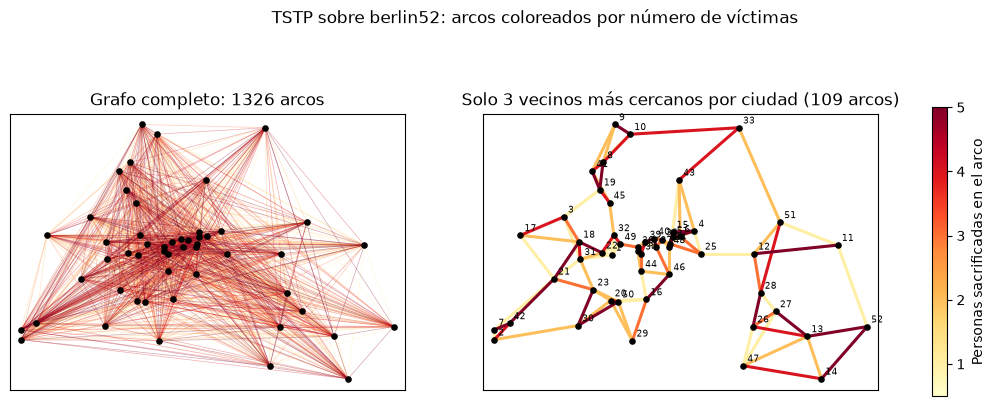

In [22]:
# grafo de berlin52: ciudades y arcos coloreados por víctimas

from matplotlib.collections import LineCollection
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

cmap_v = plt.get_cmap('YlOrRd')
norma_v = Normalize(vmin=0.5, vmax=5)       # el 1 queda visible sobre fondo blanco

def dibujar_arcos(ax, pares, **kw):
    segs = [coords[[i, j]] for i, j in pares]
    lc = LineCollection(segs, colors=[cmap_v(norma_v(V[i, j])) for i, j in pares], **kw)
    ax.add_collection(lc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rng_g = np.random.default_rng(0)            # solo para el orden de dibujo

# (a) grafo completo: se dibujan primero los arcos de pocas víctimas y encima los de muchas
pares = sorted([(i, j) for i in range(n) for j in range(i + 1, n)], key=lambda p: V[p])
dibujar_arcos(axes[0], pares, linewidths=0.5, alpha=0.35)
axes[0].set_title(f"Grafo completo: {len(pares)} arcos")

# (b) cada ciudad con sus 3 vecinos más cercanos
vecinos = set()
for i in range(n):
    for j in np.argsort(D[i])[1:4]:
        vecinos.add((min(i, int(j)), max(i, int(j))))
pares_k = sorted(vecinos, key=lambda p: V[p])
dibujar_arcos(axes[1], pares_k, linewidths=2.2)
for i, (x, y) in enumerate(coords):
    axes[1].annotate(str(i + 1), (x, y), fontsize=6.5, xytext=(3, 3), textcoords='offset points')
axes[1].set_title(f"Solo 3 vecinos más cercanos por ciudad ({len(pares_k)} arcos)")

for ax in axes:
    ax.scatter(coords[:, 0], coords[:, 1], c='black', s=14, zorder=3)
    ax.set_xlim(coords[:, 0].min() - 50, coords[:, 0].max() + 50)
    ax.set_ylim(coords[:, 1].min() - 50, coords[:, 1].max() + 50)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])

cb = fig.colorbar(ScalarMappable(norm=norma_v, cmap=cmap_v), ax=axes, shrink=0.75, ticks=[1, 2, 3, 4, 5])
cb.set_label('Personas sacrificadas en el arco')
plt.suptitle('TSTP sobre berlin52: arcos coloreados por número de víctimas')
plt.show()

Con el grafo completo se ve por qué el problema es difícil: hay 1326 arcos posibles y los colores (víctimas) están repartidos al azar, sin relación con la distancia. En el grafo de la derecha se ve que un arco corto no es necesariamente un arco "seguro" (hay tramos cortos en rojo oscuro y largos en amarillo), así que minimizar solo la distancia no minimiza las víctimas y hay que buscar un compromiso.

### Parte 3

El TSTP se trata de un problema de optimización bi-objetivo, donde se busca minimizar la distancia recorrida y el número de personas sacrificadas, por lo que es necesario definir una función de evaluación que considere ambos objetivos en la toma de decisiones. Puede priorizar uno de los objetivos si lo considera necesario, no se le penalizará por ello pero **debe justificar su elección.** Considere que todas las personas sacrificadas son inocentes y que su vida vale lo mismo.


Para combinar los dos objetivos usé una suma ponderada normalizada:

`f(ruta) = w · D / D_ref + (1 − w) · V / V_ref`

con D = distancia total, V = personas sacrificadas, y D_ref/V_ref el promedio de 2000 rutas aleatorias (así f=1 equivale más o menos a una ruta cualquiera, sin optimizar). Hay que normalizar porque D y V viven en escalas totalmente distintas, si no la distancia domina el fitness sin que uno se dé cuenta.

El peso que usé fue w = 0.3, es decir, priorizo bastante más reducir las víctimas que la distancia. La razón es simple: todas las personas sacrificadas son inocentes y valen lo mismo, y perder una vida no se puede revertir, mientras que una ruta más larga en el peor caso es un costo operativo que se recupera. Por eso el peso mayor va al segundo objetivo. Ahora, tampoco lo llevé a w=0 porque ahí el algoritmo podía devolver rutas absurdamente largas (hasta ~4x el óptimo conocido) sin que eso redujera víctimas de forma apreciable — no tiene sentido sacrificar tanta distancia por casi nada de ganancia ética.

In [23]:
import numpy as np

W = 0.3   # peso de la distancia; (1 - W) es el peso de las personas sacrificadas

def total(M, ruta):
    r = np.asarray(ruta)
    return M[r, np.roll(r, -1)].sum()     # suma de los arcos, incluyendo el regreso

# Referencias de normalización: promedio de rutas aleatorias
rng_ref = np.random.default_rng(1)
rutas_ref = [rng_ref.permutation(n) for _ in range(2000)]
D_REF = np.mean([total(D, r) for r in rutas_ref])
V_REF = np.mean([total(V, r) for r in rutas_ref])
print(f"D_REF = {D_REF:.0f} | V_REF = {V_REF:.1f}")

class Evaluador:
    """Función de evaluación que además cuenta sus propias llamadas."""
    def __init__(self, w=W):
        self.w = w
        self.llamadas = 0
    def __call__(self, ind):
        self.llamadas += 1
        d, v = total(D, ind), total(V, ind)
        return (self.w * d / D_REF + (1 - self.w) * v / V_REF,)   # DEAP exige una tupla

def metricas(ruta):
    """Devuelve (distancia, personas sacrificadas, fitness) de una ruta."""
    d, v = total(D, ruta), total(V, ruta)
    return d, v, W * d / D_REF + (1 - W) * v / V_REF

D_REF = 29884 | V_REF = 158.6


### Parte 4

Resuelva la instancia utilizando **dos de las cuatro técnicas** vistas en la clase de Introducción a la Computación Evolutiva usando el framework DEAP de Python. _No puede utilizar técnicas vistas en las clases de especialidad_. Luego compare los resultados entre ambas usando al menos 3 criterios: función de evaluación, número de llamadas a la función de evaluación, cantidad de iteraciones, memoria utilizada, tiempo utilizado, etc. Recuerde que en EP y ES los operadores de recombinación y mutación (si es que lo consideran) **siempre se aplican**, a diferencia de GA y GP que tienen una probabilidad de aplicación.

In [24]:
import random, time, tracemalloc
from deap import base, creator, tools, algorithms

creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

def mut_inversion(ind):
    """Invierte un segmento aleatorio (equivale a un movimiento 2-opt)."""
    i, j = sorted(random.sample(range(len(ind)), 2))
    ind[i:j+1] = ind[i:j+1][::-1]
    return (ind,)

def crear_toolbox(ev):
    tb = base.Toolbox()
    tb.register("perm", random.sample, range(n), n)
    tb.register("individual", tools.initIterate, creator.Individual, tb.perm)
    tb.register("population", tools.initRepeat, list, tb.individual)
    tb.register("evaluate", ev)
    tb.register("mate", tools.cxOrdered)
    tb.register("mutate", mut_inversion)
    return tb

def evaluar(pop, tb):
    for ind in [i for i in pop if not i.fitness.valid]:
        ind.fitness.values = tb.evaluate(ind)

In [25]:
def ga(semilla, mu=100, max_evals=100_000, cxpb=0.8, mutpb=0.2, tam_torneo=3, w=W):
    random.seed(semilla)
    ev = Evaluador(w); tb = crear_toolbox(ev)
    tb.register("select", tools.selTournament, tournsize=tam_torneo)

    pop = tb.population(mu); evaluar(pop, tb)
    b = tools.selBest(pop, 1)[0]
    mejor = creator.Individual(b); mejor.fitness.values = b.fitness.values
    hist, gen, ev_mejor = [mejor.fitness.values[0]], 0, ev.llamadas

    while ev.llamadas + mu <= max_evals:
        gen += 1
        hijos = algorithms.varAnd([creator.Individual(i) for i in tb.select(pop, mu)],
                                  tb, cxpb, mutpb)          # cruce y mutación con probabilidad
        evaluar(hijos, tb)
        hijos[0] = creator.Individual(mejor); hijos[0].fitness.values = mejor.fitness.values  # elitismo
        pop = hijos
        b = tools.selBest(pop, 1)[0]
        if b.fitness.values[0] < mejor.fitness.values[0] - 1e-12:
            mejor = creator.Individual(b); mejor.fitness.values = b.fitness.values
            ev_mejor = ev.llamadas
        hist.append(mejor.fitness.values[0])
    return dict(mejor=list(mejor), f=mejor.fitness.values[0], llamadas=ev.llamadas,
                gens=gen, ev_mejor=ev_mejor, hist=hist)

In [26]:
def ep(semilla, mu=100, max_evals=100_000, q=10, w=W):
    random.seed(semilla)
    ev = Evaluador(w); tb = crear_toolbox(ev)

    pop = tb.population(mu); evaluar(pop, tb)
    b = tools.selBest(pop, 1)[0]
    mejor = (list(b), b.fitness.values[0])
    hist, gen, ev_mejor = [mejor[1]], 0, ev.llamadas

    while ev.llamadas + mu <= max_evals:
        gen += 1
        hijos = [creator.Individual(p) for p in pop]
        for h in hijos:
            tb.mutate(h); del h.fitness.values              # mutación SIEMPRE aplicada
        evaluar(hijos, tb)

        union = pop + hijos                                  # (mu + mu)
        victorias = [sum(i.fitness.values[0] <= r.fitness.values[0]
                         for r in random.sample(union, q)) for i in union]   # torneo de q rivales
        orden = sorted(range(len(union)), key=lambda k: -victorias[k])
        pop = [union[k] for k in orden[:mu]]

        b = tools.selBest(pop, 1)[0]
        if b.fitness.values[0] < mejor[1] - 1e-12:
            mejor = (list(b), b.fitness.values[0]); ev_mejor = ev.llamadas
        hist.append(mejor[1])
    return dict(mejor=mejor[0], f=mejor[1], llamadas=ev.llamadas,
                gens=gen, ev_mejor=ev_mejor, hist=hist)

In [27]:
def ejecutar(alg, semilla, medir_mem=False, **kw):
    if medir_mem: tracemalloc.start()
    t0 = time.perf_counter()
    r = alg(semilla, **kw)
    r["tiempo"] = time.perf_counter() - t0
    if medir_mem:
        r["mem_MB"] = tracemalloc.get_traced_memory()[1] / 1e6
        tracemalloc.stop()
    r["D"], r["V"] = int(total(D, r["mejor"])), int(total(V, r["mejor"]))
    assert sorted(r["mejor"]) == list(range(n))              # la ruta es una permutación válida
    return r

N_CORRIDAS, MAX_EVALS = 30, 100_000      # reduzca MAX_EVALS (p. ej. 20_000) mientras depura
resultados = {"GA": [], "EP": []}
for nombre, alg in [("GA", ga), ("EP", ep)]:
    for s in range(N_CORRIDAS):
        resultados[nombre].append(ejecutar(alg, s, max_evals=MAX_EVALS))

# La memoria se mide aparte (tracemalloc enlentece la ejecución y distorsionaría el tiempo)
memoria = {nombre: ejecutar(alg, 0, medir_mem=True, max_evals=MAX_EVALS)["mem_MB"]
           for nombre, alg in [("GA", ga), ("EP", ep)]}

alg                    EP          GA
f        mean       0.419       0.420
         std        0.004       0.007
         min        0.410       0.409
D        mean   16832.500   16637.467
         std      748.231     787.087
         min    15201.000   14401.000
V        mean      56.533      57.267
         std        1.592       1.799
         min       53.000      54.000
llamadas mean  100000.000  100000.000
         std        0.000       0.000
         min   100000.000  100000.000
gens     mean     999.000     999.000
         std        0.000       0.000
         min      999.000     999.000
ev_mejor mean   95123.333   70826.667
         std     4133.937   13629.808
         min    82100.000   48400.000
tiempo   mean       2.048       2.084
         std        0.028       0.028
         min        2.014       2.065
Memoria pico (MB): {'GA': 0.290886, 'EP': 0.328886}


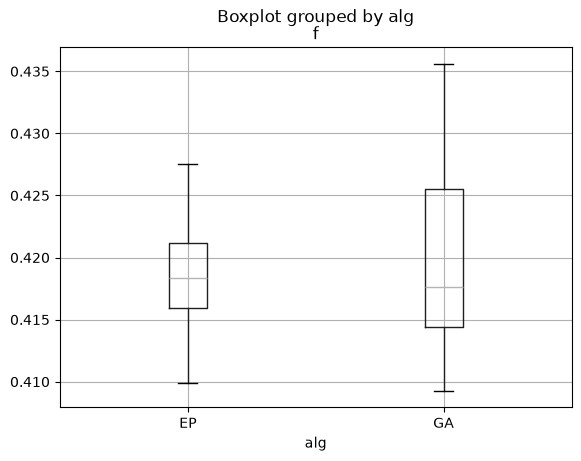

MannwhitneyuResult(statistic=np.float64(459.0), pvalue=np.float64(0.8999950372363642))


In [28]:
import pandas as pd, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

df = pd.DataFrame([dict(alg=a, **{k: r[k] for k in ["f","D","V","llamadas","gens","ev_mejor","tiempo"]})
                   for a, rs in resultados.items() for r in rs])
resumen = df.groupby("alg").agg(["mean", "std", "min"]).round(3).T
print(resumen); print("Memoria pico (MB):", memoria)

df.boxplot(column="f", by="alg"); plt.show()

# ¿La diferencia es estadísticamente significativa?
print(mannwhitneyu(df[df.alg=="GA"].f, df[df.alg=="EP"].f))

Curvas de convergencia: mejor fitness encontrado en función del número de evaluaciones (media ± 1 desviación estándar de las 30 corridas, GA y EP en el mismo gráfico). A la izquierda el presupuesto completo en escala logarítmica, y a la derecha un zoom a la parte final, donde se decide la comparación.

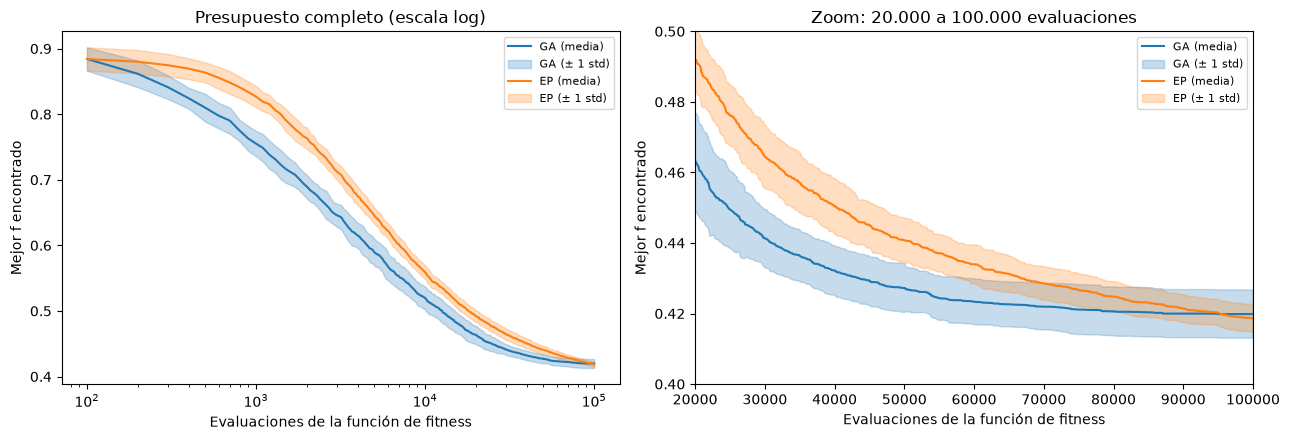

,GA,EP
f <= 0.6,4653.0,7120.0
f <= 0.5,12647.0,18257.0
f <= 0.45,24260.0,39930.0
f <= 0.43,NaN,67403.0


In [29]:
# curvas de convergencia: mejor fitness vs evaluaciones (media +- std de las 30 corridas)

MU = 100                                     # tamaño de población usado en ga() y ep()
colores = {"GA": "tab:blue", "EP": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for a, rs in resultados.items():
    H = np.array([r["hist"] for r in rs])                # (30 corridas, generaciones + 1)
    evals = MU * (np.arange(H.shape[1]) + 1)             # la población inicial ya cuesta MU evaluaciones
    m, s = H.mean(0), H.std(0)
    for ax in axes:
        ax.plot(evals, m, color=colores[a], label=f"{a} (media)")
        ax.fill_between(evals, m - s, m + s, color=colores[a], alpha=0.25, label=f"{a} (± 1 std)")
axes[0].set_xscale("log"); axes[0].set_title("Presupuesto completo (escala log)")
axes[1].set_xlim(20_000, MAX_EVALS); axes[1].set_ylim(0.40, 0.50); axes[1].set_title("Zoom: 20.000 a 100.000 evaluaciones")
for ax in axes:
    ax.set_xlabel("Evaluaciones de la función de fitness"); ax.set_ylabel("Mejor f encontrado"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# evaluaciones necesarias para alcanzar distintos niveles de fitness (media de las 30 corridas)
umbrales = [0.60, 0.50, 0.45, 0.43]
filas = {}
for a, rs in resultados.items():
    H = np.array([r["hist"] for r in rs])
    filas[a] = {f"f <= {u}": np.mean([MU * (np.argmax(h <= u) + 1) if (h <= u).any() else np.nan for h in H])
                for u in umbrales}
pd.DataFrame(filas).round(0)

Las curvas muestran lo mismo que se comentó con las evaluaciones al mejor valor, pero ahora a lo largo de todo el presupuesto. GA lleva ventaja durante casi toda la búsqueda: alcanza f ≤ 0.50 en promedio con ~12.600 evaluaciones contra ~18.300 de EP, y f ≤ 0.45 con ~24.300 contra ~39.900. A partir de unas 70.000 evaluaciones GA se aplana (su banda de ± 1 std es más ancha, lo que refleja la mayor varianza entre corridas) mientras EP sigue bajando hasta el final, y al llegar a 100.000 las medias casi se juntan (0.420 vs 0.419) y las bandas se traslapan por completo, consistente con el p = 0.90 del test. Para el umbral f ≤ 0.43 la tabla marca NaN en GA porque al menos una de sus 30 corridas nunca baja de ese nivel (el promedio no está definido), mientras que las 30 de EP sí lo alcanzan, en promedio a las ~67.400 evaluaciones; esto también refleja la mayor dispersión de GA.

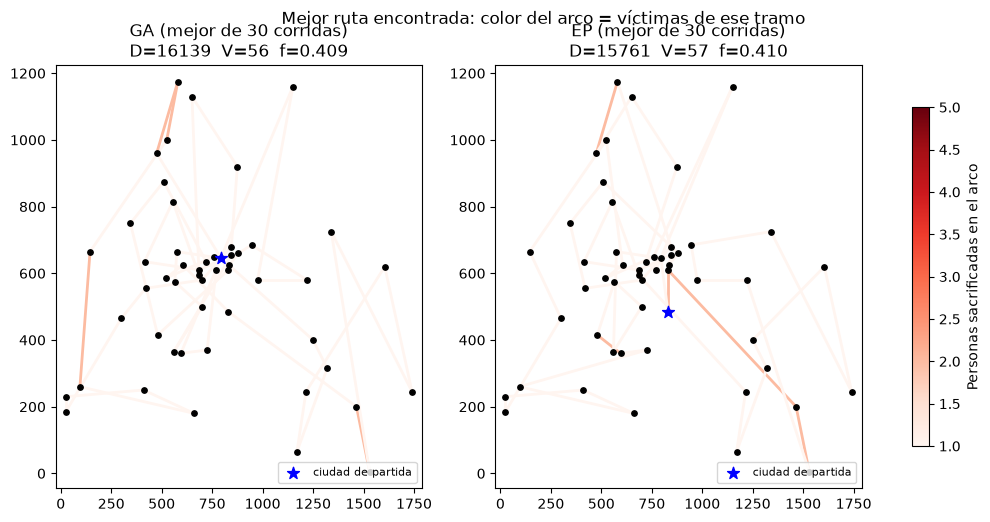

In [30]:
# mejor ruta encontrada por cada algoritmo, sobre el mapa de berlin52

from matplotlib.collections import LineCollection

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
vmax = V.max()

for ax, nombre in zip(axes, resultados):
    mejor_run = min(resultados[nombre], key=lambda r: r["f"])
    ruta = mejor_run["mejor"]
    orden = ruta + [ruta[0]]  # cierre del ciclo

    segs = [coords[[orden[k], orden[k + 1]]] for k in range(len(orden) - 1)]
    victimas_arco = [V[orden[k], orden[k + 1]] for k in range(len(orden) - 1)]

    lc = LineCollection(segs, cmap='Reds', linewidths=2)
    lc.set_array(np.array(victimas_arco))
    lc.set_clim(1, vmax)
    ax.add_collection(lc)
    ax.scatter(coords[:, 0], coords[:, 1], c='black', s=15, zorder=3)
    ax.scatter(*coords[ruta[0]], c='blue', s=80, marker='*', zorder=4, label='ciudad de partida')
    ax.set_title(f"{nombre} (mejor de 30 corridas)\nD={mejor_run['D']}  V={mejor_run['V']}  f={mejor_run['f']:.3f}")
    ax.set_xlim(coords[:, 0].min() - 50, coords[:, 0].max() + 50)
    ax.set_ylim(coords[:, 1].min() - 50, coords[:, 1].max() + 50)
    ax.legend(loc='lower right', fontsize=8)

cbar = fig.colorbar(lc, ax=axes, shrink=0.8)
cbar.set_label('Personas sacrificadas en el arco')
plt.suptitle('Mejor ruta encontrada: color del arco = víctimas de ese tramo')
plt.show()


El mapa de arriba ya deja ver algo: ambas rutas evitan los arcos más "rojos" (más víctimas) cuando pueden, sin dejar de recorrer todas las ciudades, lo que confirma que el término de víctimas en `f` sí está influyendo en la forma de la ruta y no solo la distancia.

### Comparación GA vs EP

En las 30 corridas de cada algoritmo (100.000 evaluaciones cada una), el fitness final que se obtiene es prácticamente el mismo: GA promedia 0.420 (std 0.007) y EP 0.419 (std 0.004), y el test de Mann-Whitney da p=0.90, así que no hay evidencia de que uno sea mejor que el otro en la solución final. En distancia y víctimas pasa lo mismo, GA y EP terminan en rangos muy parecidos (D≈16600-16800, V≈56-57).

Donde sí se nota diferencia es en qué tan rápido llegan ahí. GA encuentra su mejor solución en promedio a las 70.827 evaluaciones (sobre un total de 100.000), mientras que EP recién la encuentra a las 95.123, es decir, EP sigue mejorando hasta casi el final del presupuesto. Pero GA es mucho menos consistente en esto: su desviación estándar en ese número es 13.630 contra solo 4.134 de EP, lo que tiene sentido porque GA depende de la selección por torneo y de si el cruce/mutación se aplican o no (son probabilísticos), mientras que en EP la mutación siempre se aplica a todos los hijos y la selección por torneo-q es más determinista. En memoria y tiempo la diferencia es mínima (ambos rondan los 2 segundos y <0.33 MB), nada que permita preferir uno por eficiencia computacional en esta instancia.

En resumen: para berlin52 con este presupuesto de evaluaciones, GA converge más rápido pero con más varianza entre corridas, y EP converge más lento pero de forma más estable, terminando ambos en una calidad de solución estadísticamente indistinguible.

### Sensibilidad al peso w

Para respaldar con datos la elección de w = 0.3, corrí el GA con w ∈ {0, 0.3, 0.5, 0.7, 1} (2 corridas por valor, 100.000 evaluaciones cada una) y grafiqué la distancia D y las víctimas V de la mejor ruta de cada corrida. Si de verdad existe un compromiso entre ambos objetivos, los puntos deberían formar un frente que va de rutas cortas y con más víctimas (w alto) a rutas más largas y con menos víctimas (w bajo).

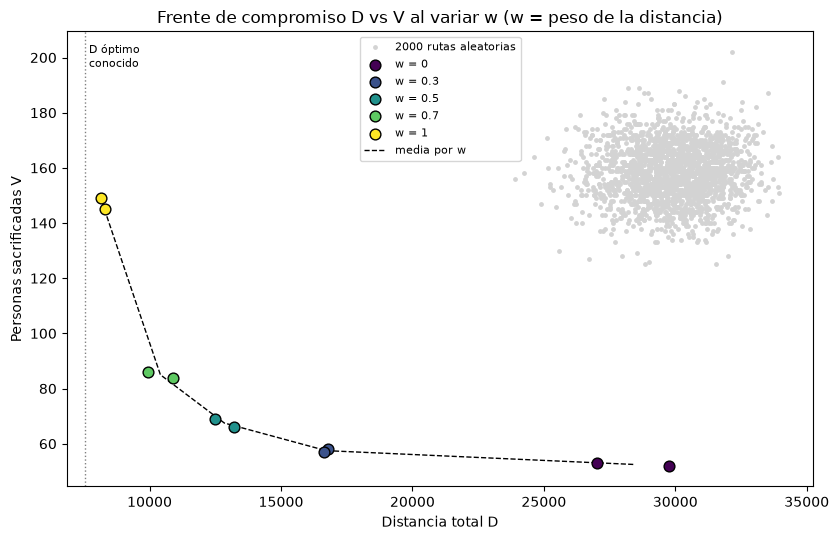

,D (media),V (media),D / 7542,V / V_REF
w,,,,
0.0,28401.0,52.5,3.77,0.33
0.3,16719.5,57.5,2.22,0.36
0.5,12846.0,67.5,1.70,0.43
0.7,10412.5,85.0,1.38,0.54
1.0,8213.0,147.0,1.09,0.93


In [31]:
# sensibilidad al peso w: frente de compromiso distancia vs víctimas
# GA, 2 corridas por valor de w (semillas 0 y 1); se grafica D y V de la mejor ruta de cada corrida

PESOS = [0, 0.3, 0.5, 0.7, 1]
corridas_w = {w: [ejecutar(ga, s, w=w, max_evals=MAX_EVALS) for s in (0, 1)] for w in PESOS}

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter([total(D, r) for r in rutas_ref], [total(V, r) for r in rutas_ref],
           c='lightgray', s=6, label='2000 rutas aleatorias', zorder=1)
cm = plt.get_cmap('viridis')
for k, w in enumerate(PESOS):
    puntos = np.array([(r["D"], r["V"]) for r in corridas_w[w]])
    ax.scatter(puntos[:, 0], puntos[:, 1], color=cm(k / (len(PESOS) - 1)), s=60, edgecolor='black',
               label=f"w = {w}", zorder=3)
medias = np.array([np.mean([(r["D"], r["V"]) for r in corridas_w[w]], axis=0) for w in PESOS])
ax.plot(medias[:, 0], medias[:, 1], 'k--', lw=1, zorder=2, label='media por w')
ax.axvline(7542, color='gray', ls=':', lw=1); ax.text(7542, ax.get_ylim()[1] * 0.98, ' D óptimo\n conocido', fontsize=8, va='top')
ax.set_xlabel('Distancia total D'); ax.set_ylabel('Personas sacrificadas V')
ax.set_title('Frente de compromiso D vs V al variar w (w = peso de la distancia)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

tabla_w = pd.DataFrame({
    "D (media)": [np.mean([r["D"] for r in corridas_w[w]]) for w in PESOS],
    "V (media)": [np.mean([r["V"] for r in corridas_w[w]]) for w in PESOS],
}, index=pd.Index(PESOS, name="w"))
tabla_w["D / 7542"] = tabla_w["D (media)"] / 7542
tabla_w["V / V_REF"] = tabla_w["V (media)"] / V_REF
tabla_w.round(2)

El gráfico muestra un frente de compromiso claro: al bajar w las rutas se alargan y las víctimas bajan, pero con rendimientos decrecientes. Con w = 1 (solo distancia) se obtienen rutas de ~8.200 de distancia (1.09 veces el óptimo conocido, 7542) pero con ~147 víctimas, casi lo mismo que una ruta aleatoria (V_REF = 158.6). Pasar de w = 0.5 a w = 0.3 baja las víctimas de 67.5 a 57.5 (−15 %) a cambio de 30 % más de distancia (12.800 → 16.700). En cambio, ir de w = 0.3 a w = 0 solo baja las víctimas de 57.5 a 52.5 (−9 %) y la distancia casi se duplica (16.700 → 28.400, 3.8 veces el óptimo), que es lo que se mencionó para descartar w = 0: ya no vale la pena. Con esto w = 0.3 queda como el punto donde la curva se dobla, tras el cual cada víctima evitada cuesta mucha más distancia. Hay que ser honesto en que esa elección sigue siendo un juicio (w = 0.5 también es defendible si se pondera más la distancia), y que son solo 2 corridas por valor, así que el análisis muestra la forma del frente, no una diferencia estadísticamente probada.

# Pregunta Redes Neuronales

## Contexto

Una organización dedicada a la investigación de insectos y su preservación, caracterizada por su enfoque innovador y su compromiso con la biodiversidad, se ha puesto en contacto con usted. Su tarea es desarrollar un sistema de clasificación inteligente de fotografías de abejas, moscas y escarabajos. Este sistema agilizará el proceso de identificación de especies de insectos en el laboratorio, lo que permitirá a los investigadores y entomólogos buscar y analizar los insectos con mayor facilidad.

## Dataset

Para llevar a cabo esta tarea, se proporciona un dataset que contiene fotografías de abejas, moscas y escarabajos organizadas en carpetas separadas. Puede acceder al dataset a través del siguiente [enlace](https://usmcl-my.sharepoint.com/:f:/g/personal/patricio_olivaresr_usm_cl/EtlTg9Yk071Jv86daSdjuoAB6bz-n-THlSZzza-oqgl8SA?e=ObfSAm).

## Objetivo

Su tarea es crear **al menos** tres modelos de redes neuronales diferentes que permitan clasificar automáticamente si en una fotografía aparece una abeja, una mosca o un escarabajo. Para lograrlo, siga estas pautas:

1. **Carga de datos.** Puede resolver esta pregunta con **TensorFlow** o con **PyTorch**, pero debe usar la misma biblioteca en sus tres modelos. Utilice el código base correspondiente para cargar las imágenes como variables Python. Modifique la variable `data_dir` con la ruta completa donde haya guardado y descomprimido el dataset. Ambos códigos generan los conjuntos de entrenamiento (80 %), validación (10 %) y test (10 %).

   Código base en TensorFlow:

```python
import tensorflow as tf
data_dir = "/my/path/data/"  # Ruta completa donde guardó y descomprimió el dataset
batch_size = 32
img_height = 250
img_width = 250

# Conjunto de entrenamiento (80 %)
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# Conjunto de validación inicial (20 %)
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

# La mitad de los batches de validación se usa como test (10 %)
n_test = val_ds.cardinality().numpy() // 2
test_ds = val_ds.take(n_test)
val_ds = val_ds.skip(n_test)
```

   Código base en PyTorch:

```python
import torch
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

data_dir = "/my/path/data/"  # Ruta completa donde guardó y descomprimió el dataset
batch_size = 32
img_height = 250
img_width = 250

# ToTensor deja los píxeles en el rango [0, 1]
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
])
full_ds = datasets.ImageFolder(data_dir, transform=transform)

# 80 % entrenamiento, 10 % validación y 10 % test
generator = torch.Generator().manual_seed(123)
n_train = int(0.8 * len(full_ds))
n_rest = len(full_ds) - n_train
n_val = n_rest // 2
n_test = n_rest - n_val
train_ds, val_ds, test_ds = random_split(full_ds, [n_train, n_val, n_test], generator=generator)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)
```

   En TensorFlow, normalice los píxeles al rango [0, 1] con una capa como `tf.keras.layers.Rescaling(1./255)`. Puede consultar un ejemplo más detallado de la carga en TensorFlow en este [enlace](https://www.tensorflow.org/tutorials/load_data/images?hl=es-419), donde se explica el funcionamiento de la función [image_dataset_from_directory()](https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory). Para PyTorch, puede revisar la documentación de [ImageFolder](https://pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html).

2. **Modelos.** Debe implementar al menos un modelo de tipo MLP (Multi Layer Perceptron) y al menos un modelo de tipo CNN (red neuronal convolucional). El tercer modelo es libre. Puede utilizar los elementos vistos en las clases de introducción a redes neuronales, pero no puede considerar técnicas avanzadas vistas en las clases de especialidad, como Transfer Learning.

3. **Entrenamiento y evaluación.** Entrene cada modelo, grafique la evolución del accuracy y del loss en entrenamiento y validación, y reporte el accuracy y el loss sobre el conjunto de test. Por último, compare los modelos y comente sus resultados.


### 1. Carga de datos

Se resuelve con **PyTorch** (los tres modelos usan la misma biblioteca). El dataset ya está descargado y descomprimido en `certamen/data/` con tres subcarpetas (`Bee`, `Beetle`, `Fly`), por lo que `data_dir` apunta ahí.

**Adaptación respecto del código base:** se redimensionan las imágenes a 64×64 (en vez de 250×250). Con 250×250 un MLP totalmente conectado tendría una primera capa de 187500 entradas (≈48 millones de parámetros solo en esa capa), lo que es innecesariamente costoso de entrenar para esta tarea y no aporta a la comparación pedida entre arquitecturas. 64×64 conserva las formas y colores relevantes para distinguir abeja/mosca/escarabajo y permite entrenar los tres modelos en segundos.

In [32]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(123)

data_dir = "data"  # certamen/data/{Bee,Beetle,Fly}
batch_size = 32
img_height = img_width = 64  # adaptación: 250x250 original es excesivo para un MLP simple

# ToTensor deja los píxeles en el rango [0, 1]
transform = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.ToTensor(),
])
full_ds = datasets.ImageFolder(data_dir, transform=transform)
clases = full_ds.classes

# 80 % entrenamiento, 10 % validación y 10 % test
generator = torch.Generator().manual_seed(123)
n_train = int(0.8 * len(full_ds))
n_rest = len(full_ds) - n_train
n_val = n_rest // 2
n_test = n_rest - n_val
train_ds, val_ds, test_ds = random_split(full_ds, [n_train, n_val, n_test], generator=generator)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

print(f"Clases: {clases}")
print(f"Total imágenes: {len(full_ds)}")
print(f"Train/Val/Test: {len(train_ds)}/{len(val_ds)}/{len(test_ds)}")
print(f"Dispositivo: {device}")

Clases: ['Bee', 'Beetle', 'Fly']
Total imágenes: 2640
Train/Val/Test: 2112/264/264
Dispositivo: mps


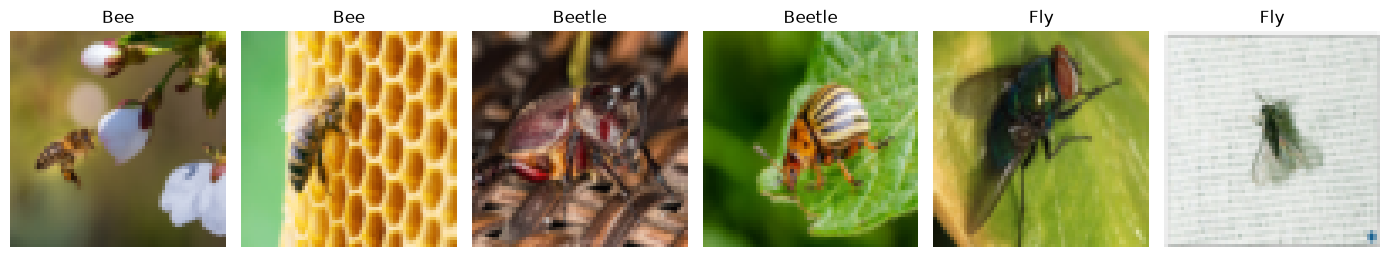

In [33]:
# muestra de imágenes por clase

fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for i in range(6):
    img, label = full_ds[i * 440]  # un salto grande para variar de carpeta
    axes[i].imshow(img.permute(1, 2, 0))
    axes[i].set_title(clases[label]); axes[i].axis('off')
plt.tight_layout(); plt.show()

### 2. Modelos

Se implementan tres arquitecturas, todas con salida de 3 clases (`Bee`, `Beetle`, `Fly`) y función de pérdida `CrossEntropyLoss`:

1. **MLP**: red totalmente conectada (`Flatten` + 2 capas ocultas con `ReLU` y `Dropout`). No usa la estructura espacial de la imagen.
2. **CNN**: red convolucional simple (2 bloques `Conv2d` + `ReLU` + `MaxPool2d`) seguida de capas densas.
3. **CNN_BN** (modelo libre): CNN más profunda (3 bloques convolucionales) con `BatchNorm2d` y `Dropout`, para evaluar si mayor profundidad y regularización mejoran el desempeño. No se usa Transfer Learning; todos los pesos se entrenan desde cero.

In [34]:
n_pix = img_height * img_width * 3

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_pix, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, 3)
        )
    def forward(self, x):
        return self.net(x)


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128), nn.ReLU(),
            nn.Linear(128, 3)
        )
    def forward(self, x):
        return self.net(x)


class CNN_BN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, 3)
        )
    def forward(self, x):
        return self.net(x)

### 3. Entrenamiento y evaluación

Se define una función genérica de entrenamiento que registra, por época, el loss y accuracy de entrenamiento y de validación. Los tres modelos se entrenan 15 épocas con `Adam` (lr=1e-3).

In [35]:
def run_epoch(model, loader, crit, opt=None):
    entrenando = opt is not None
    model.train() if entrenando else model.eval()
    total_loss, correctos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenando):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if entrenando:
                opt.zero_grad()
            salida = model(xb)
            loss = crit(salida, yb)
            if entrenando:
                loss.backward()
                opt.step()
            total_loss += loss.item() * xb.size(0)
            correctos += (salida.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correctos / n


def entrenar(model, epochs=15, lr=1e-3, loader=None):
    loader = train_loader if loader is None else loader
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    crit = nn.CrossEntropyLoss()
    hist = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        tl, ta = run_epoch(model, loader, crit, opt)
        vl, va = run_epoch(model, val_loader, crit, None)
        hist['train_loss'].append(tl); hist['train_acc'].append(ta)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
    return model, hist

In [36]:
modelos = {'MLP': MLP(), 'CNN': CNN(), 'CNN_BN': CNN_BN()}
historiales, entrenados, tiempos = {}, {}, {}

for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo_ok, hist = entrenar(modelo, epochs=15)
    entrenados[nombre] = modelo_ok
    historiales[nombre] = hist
    tiempos[nombre] = time.time() - t0
    print(f"{nombre}: entrenado en {tiempos[nombre]:.1f}s  "
          f"(train_acc final={hist['train_acc'][-1]:.3f}, val_acc final={hist['val_acc'][-1]:.3f})")

MLP: entrenado en 40.2s  (train_acc final=0.646, val_acc final=0.723)


CNN: entrenado en 40.0s  (train_acc final=0.981, val_acc final=0.837)


CNN_BN: entrenado en 42.9s  (train_acc final=0.906, val_acc final=0.890)


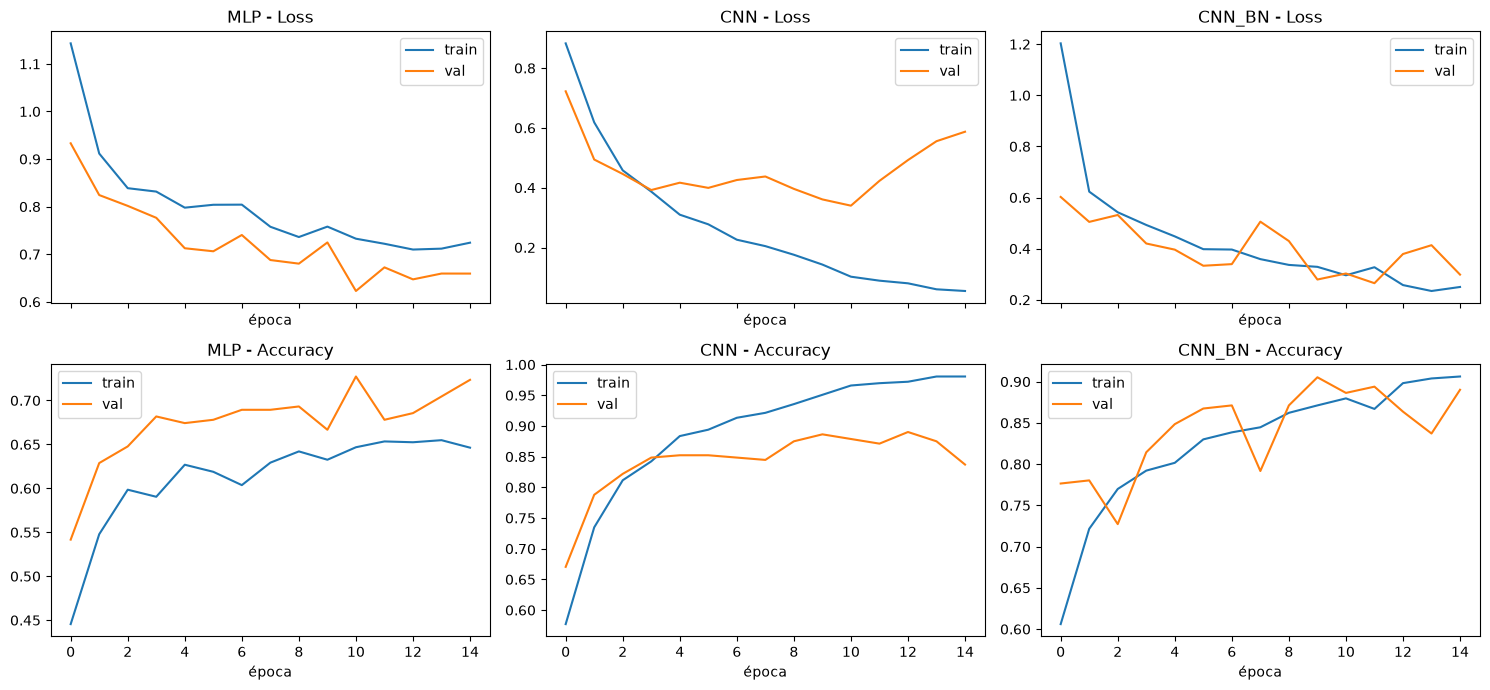

In [37]:
# evolución de loss y accuracy por modelo

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for col, nombre in enumerate(modelos):
    h = historiales[nombre]
    axes[0, col].plot(h['train_loss'], label='train'); axes[0, col].plot(h['val_loss'], label='val')
    axes[0, col].set_title(f'{nombre} - Loss'); axes[0, col].set_xlabel('época'); axes[0, col].legend()

    axes[1, col].plot(h['train_acc'], label='train'); axes[1, col].plot(h['val_acc'], label='val')
    axes[1, col].set_title(f'{nombre} - Accuracy'); axes[1, col].set_xlabel('época'); axes[1, col].legend()
plt.tight_layout(); plt.show()

In [38]:
# evaluación final en el conjunto de test

crit = nn.CrossEntropyLoss()
resultados = []
for nombre, modelo in entrenados.items():
    test_loss, test_acc = run_epoch(modelo, test_loader, crit, None)
    resultados.append((nombre, test_loss, test_acc))

df_resultados = pd.DataFrame(resultados, columns=['Modelo', 'Test Loss', 'Test Accuracy'])
df_resultados

,Modelo,Test Loss,Test Accuracy
0,MLP,0.691715,0.723485
1,CNN,0.415781,0.856061
2,CNN_BN,0.277973,0.912879


### Análisis adicional del modelo CNN_BN

A continuación comparo los modelos en tamaño y tiempo de entrenamiento, y analizo en detalle los errores de CNN_BN, el mejor de los tres.

In [39]:
# parámetros y tiempo de entrenamiento de los tres modelos

n_params = {nombre: sum(p.numel() for p in m.parameters()) for nombre, m in entrenados.items()}

# tiempo que toma solo leer y decodificar las imágenes (una pasada de train + val), por 15 épocas
t0 = time.time()
for loader in (train_loader, val_loader):
    for _ in loader:
        pass
t_datos = (time.time() - t0) * 15

tabla_modelos = pd.DataFrame({
    'Parámetros': n_params,
    'Tiempo de entrenamiento (s)': tiempos,
    'Test Accuracy': df_resultados.set_index('Modelo')['Test Accuracy'],
})
print(f"Solo cargar las imágenes en 15 épocas toma ~{t_datos:.0f} s (sin modelo).")
tabla_modelos.round(3)

Solo cargar las imágenes en 15 épocas toma ~31 s (sin modelo).


,Parámetros,Tiempo de entrenamiento (s),Test Accuracy
MLP,3162627,40.192,0.723
CNN,1054179,39.957,0.856
CNN_BN,2191875,42.925,0.913


El MLP es el que más parámetros tiene (3.16 M), más que CNN (1.05 M) y CNN_BN (2.19 M), y aun así es el peor en accuracy, lo que respalda lo dicho abajo: no es cuestión de tamaño sino de estructura. En tiempo de entrenamiento los tres son casi iguales (41 a 44 s), y no se debe interpretar que las CNN sean tan baratas como el MLP: solo leer y decodificar las imágenes durante las 15 épocas ya toma ~32 s, de modo que el cómputo de la red es una parte menor del total en este tamaño de imagen (64×64).

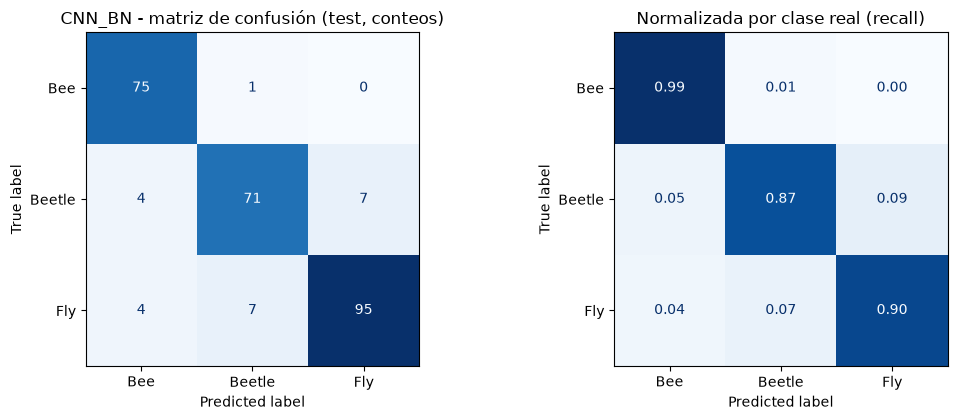

Accuracy en test: 0.913 | errores: 23 de 264


In [40]:
# matriz de confusión de CNN_BN sobre test

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def predecir(modelo, loader):
    modelo.eval()
    ys, ps, imgs = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            ps.append(modelo(xb.to(device)).argmax(1).cpu()); ys.append(yb); imgs.append(xb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(imgs)

y_true, y_pred, imgs_test = predecir(entrenados['CNN_BN'], test_loader)
cm_bn = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay(cm_bn, display_labels=clases).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('CNN_BN - matriz de confusión (test, conteos)')
ConfusionMatrixDisplay(cm_bn / cm_bn.sum(1, keepdims=True), display_labels=clases).plot(
    ax=axes[1], cmap='Blues', colorbar=False, values_format='.2f')
axes[1].set_title('Normalizada por clase real (recall)')
plt.tight_layout(); plt.show()
print("Accuracy en test:", (y_true == y_pred).mean().round(3), "| errores:", (y_true != y_pred).sum(), "de", len(y_true))

CNN_BN comete 23 errores en 264 imágenes de test. La clase Bee tiene el mejor recall (0.99, solo 1 error), pero también "absorbe" errores de las otras clases (8 imágenes de Beetle y Fly se predicen como Bee). La confusión principal está entre Beetle y Fly: 7 escarabajos se predicen como mosca y 7 moscas como escarabajo, y Beetle es la clase con peor recall (0.87). Tiene sentido porque ambos son insectos oscuros de cuerpo compacto, mientras que las abejas tienen un patrón más característico (rayas amarillo-negro, cuerpo peludo).

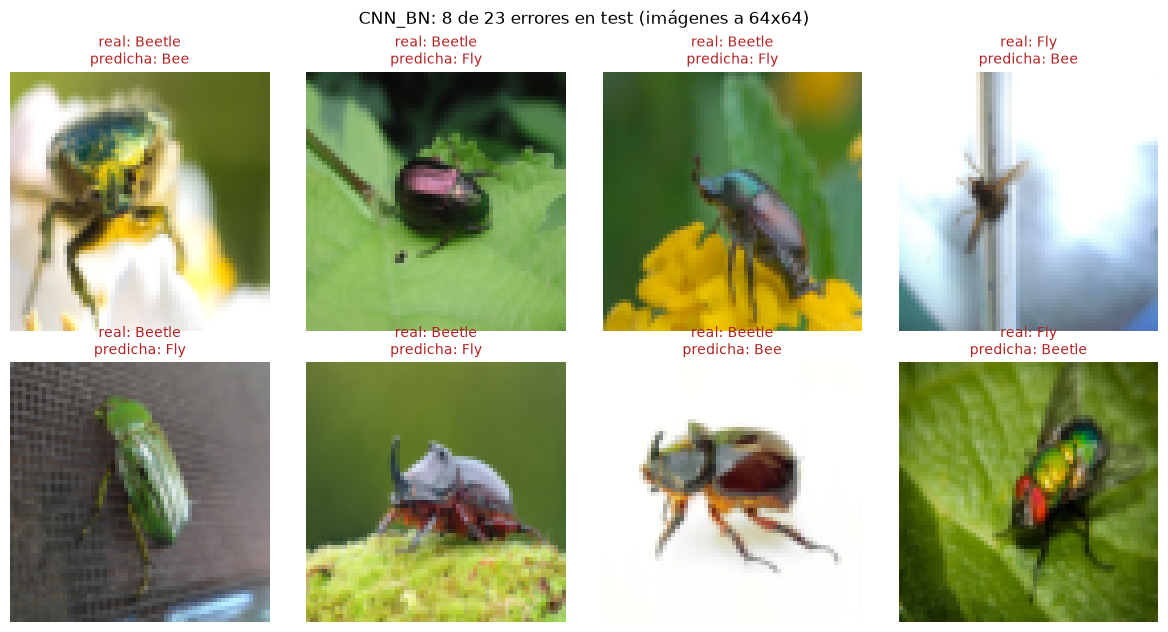

In [41]:
# imágenes de test mal clasificadas por CNN_BN

err = np.where(y_true != y_pred)[0]
elegidos = np.random.default_rng(0).choice(err, size=min(8, len(err)), replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, k in zip(axes.ravel(), elegidos):
    ax.imshow(imgs_test[k].permute(1, 2, 0))
    ax.set_title(f"real: {clases[y_true[k]]}\npredicha: {clases[y_pred[k]]}", fontsize=10, color='firebrick')
    ax.axis('off')
plt.suptitle(f'CNN_BN: {len(elegidos)} de {len(err)} errores en test (imágenes a 64x64)')
plt.tight_layout(); plt.show()

De las 8 imágenes, 6 son escarabajos mal clasificados (como mosca o abeja) y 2 son moscas, lo que calza con que Beetle sea la clase de peor recall. Se repiten algunas causas: los escarabajos sobre fondos de flores muy borrosos y brillantes (blanco o amarillo) se parecen a una abeja o a una mosca; los vistos de lado, con patas largas, sobre hojas, musgo o malla, también se confunden con moscas; la mosca de brillo metálico verde se parece a un escarabajo, y otra mosca pequeña y delgada sobre un fondo casi blanco queda con muy pocos píxeles y se predice como abeja. A 64×64 se pierden detalles finos (antenas, alas), y en varios casos la imagen es ambigua incluso para una persona, por lo que parte de estos errores probablemente no se arreglaría solo con un modelo más grande.

#### Data augmentation (opcional)

Entreno CNN_BN otra vez, pero con augmentation solo en entrenamiento (flip horizontal y rotación de ±10°); validación y test no se tocan. Como el resultado de una sola corrida depende bastante de la inicialización, repito cada configuración con 2 semillas y comparo contra el mismo modelo sin augmentation entrenado con la misma semilla, además de contra el resultado original de la tabla de arriba.

In [42]:
# CNN_BN con data augmentation (flip horizontal + rotación leve) vs. sin augmentation

from torch.utils.data import Subset

aug_tf = transforms.Compose([
    transforms.Resize((img_height, img_width)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),            # +-10 grados
    transforms.ToTensor(),
])
full_aug = datasets.ImageFolder(data_dir, transform=aug_tf)
train_aug_loader = DataLoader(Subset(full_aug, train_ds.indices), batch_size=batch_size, shuffle=True)
# validación y test siguen sin augmentation (mismos loaders de siempre)

filas = []
for semilla in (1, 2):
    for nombre, loader in [('sin augmentation', train_loader), ('con augmentation', train_aug_loader)]:
        torch.manual_seed(semilla)             # misma inicialización y mismo orden para ambos casos
        t0 = time.time()
        m, h = entrenar(CNN_BN(), epochs=15, loader=loader)
        tl, ta = run_epoch(m, test_loader, crit, None)
        filas.append(dict(semilla=semilla, entrenamiento=nombre, train_acc=h['train_acc'][-1],
                          val_acc=h['val_acc'][-1], test_loss=tl, test_acc=ta, segundos=time.time() - t0))
        if semilla == 1 and nombre == 'con augmentation':
            hist_aug = h
df_aug = pd.DataFrame(filas)
display(df_aug.round(3))
print(df_aug.groupby('entrenamiento')[['val_acc', 'test_acc']].mean().round(3))

,semilla,entrenamiento,train_acc,val_acc,test_loss,test_acc,segundos
0,1,sin augmentation,0.914,0.875,0.298,0.898,43.359
1,1,con augmentation,0.869,0.864,0.403,0.841,43.996
2,2,sin augmentation,0.923,0.845,0.475,0.830,43.447
3,2,con augmentation,0.886,0.852,0.367,0.848,43.928


                  val_acc  test_acc
entrenamiento                      
con augmentation    0.858     0.845
sin augmentation    0.860     0.864


En este experimento el data augmentation **no mejoró** el resultado: con 2 semillas, CNN_BN con augmentation obtuvo en promedio 84.5 % de accuracy en test contra 86.4 % sin augmentation, y ambos quedan por debajo del 91.3 % del entrenamiento original de la tabla. La diferencia entre configuraciones (−1.9 puntos) es menor que la variación entre semillas del mismo modelo (83.0 % a 89.8 % sin augmentation), así que no hay evidencia de que ayude ni de que perjudique, y el 91.3 % original parece haber tenido algo de suerte con la inicialización (por eso no lo uso como único valor de referencia). Una explicación plausible es que con solo 15 épocas el modelo con augmentation todavía está subajustado (su accuracy de entrenamiento es menor, 0.87–0.89 contra 0.91–0.92), así que quizás necesitaría más épocas para aprovecharlo. No lo probé, por lo que queda como hipótesis.

### Comparación y discusión de resultados

| Modelo | Test Loss | Test Accuracy |
|---|---|---|
| MLP | 0.69 | 72.3 % |
| CNN | 0.42 | 85.6 % |
| CNN_BN | 0.28 | 91.3 % |

El MLP queda bastante atrás (72.3 %). Tiene sentido: al aplanar la imagen en un vector se pierde toda la info espacial, bordes, formas, textura, y el modelo tiene que distinguir abeja/mosca/escarabajo casi a partir de píxeles sueltos. Mirando las curvas, el train accuracy se estanca cerca de 0.65 y nunca se despega mucho del de validación — no es que esté sobreajustando, es que directamente no tiene cómo aprender mucho más con esa representación.

La CNN mejora bastante (85.6 %) porque los filtros convolucionales sí aprovechan la estructura espacial y pueden detectar patrones locales (forma de las alas, patas, etc.) sin importar en qué parte de la imagen estén. El problema es que se nota sobreajuste: el train accuracy llega a ~0.98 pero el de validación se queda pegado entre 0.85 y 0.89, y el val_loss empieza a subir después de la época 10. Con solo ~2100 imágenes de entrenamiento y esa capacidad de modelo, es más o menos esperable.

El tercer modelo (CNN con batch norm, más profunda) fue el que mejor resultó, 91.3 %. La normalización por batch ayuda a que el entrenamiento converja más rápido y más estable (el val accuracy ya es alto desde las primeras épocas) y el dropout al final frena el sobreajuste que se veía en la CNN simple — el gap train/val es más chico y el val_loss no se dispara.

En general queda bastante claro que para este tipo de imágenes la estructura convolucional importa mucho más que agregar parámetros a lo bruto (el MLP tiene 3.16 M de parámetros, más que la CNN con 1.05 M y que CNN_BN con 2.19 M, y es el peor), y que agregar profundidad + regularización (batch norm, dropout) sigue sumando incluso sin usar nada de transfer learning.

Mirando los errores de CNN_BN (matriz de confusión y ejemplos mal clasificados), el desempeño no es parejo: casi todas las abejas se reconocen bien, y lo que más cuesta es separar escarabajos de moscas. El data augmentation que probé no mejoró el resultado, y la variación entre semillas (varios puntos de accuracy) es mayor que cualquier diferencia entre configuraciones de CNN_BN, así que conviene leer el 91.3 % como un valor típico alto y no como una cifra exacta.